# Teaching a Machine to Read Handwriting
### Exploratory analysis and a convolutional neural network for the UCI Optical Recognition of Handwritten Digits data

**Vinith A (25ADL10)**, III Year B.Tech. Artificial Intelligence and Data Science, KPR Institute of Engineering and Technology  
U21ADP05 Exploratory Data Analysis and Visualization, Assignment II (case study)

The project is organised as five scripts in `src/`, one per group of Fry's visualization stages. This notebook runs them in order and shows their output.

| Script | Fry stages | What it does |
|---|---|---|
| `common.py` | acquire, parse | reads the UCI zip, decodes the original `.Z` bitmaps, plotting style |
| `step2_explore.py` | filter, mine, represent | audit, distributions, correlation, PCA, t-SNE, outliers, writer shift |
| `step3_train_cnn.py` | mine | CNN, hyper-parameter grid, occlusion sensitivity, baselines |
| `step4_evaluate.py` | represent, refine | learning curves, confusion matrix, ROC, calibration, errors |
| `step5_dashboard.py` | interact | builds the Digit Lab page |

In [1]:
import os, sys, json
from pathlib import Path
from IPython.display import Image, display
SRC = Path.cwd().parent / 'src' if Path.cwd().name == 'notebooks' else Path.cwd() / 'src'
sys.path.insert(0, str(SRC)); os.chdir(SRC)
FIG = SRC.parent / 'figures'
def show(*names):
    for n in names:
        display(Image(filename=str(FIG / f'{n}.png'), width=900))

## 1. Acquire and parse
The 64-feature tables and the original 32 x 32 bitmaps are read directly from `data/optdigits.zip`.

In [2]:
import common as C
tra, tes = C.load_tables()
print(tra.shape, tes.shape)
tra.head()

(3823, 65) (1797, 65)


,p00,p01,p02,p03,p04,p05,p06,p07,p10,p11,...,p67,p70,p71,p72,p73,p74,p75,p76,p77,digit
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


## 2. Filter and mine: data audit and exploratory analysis

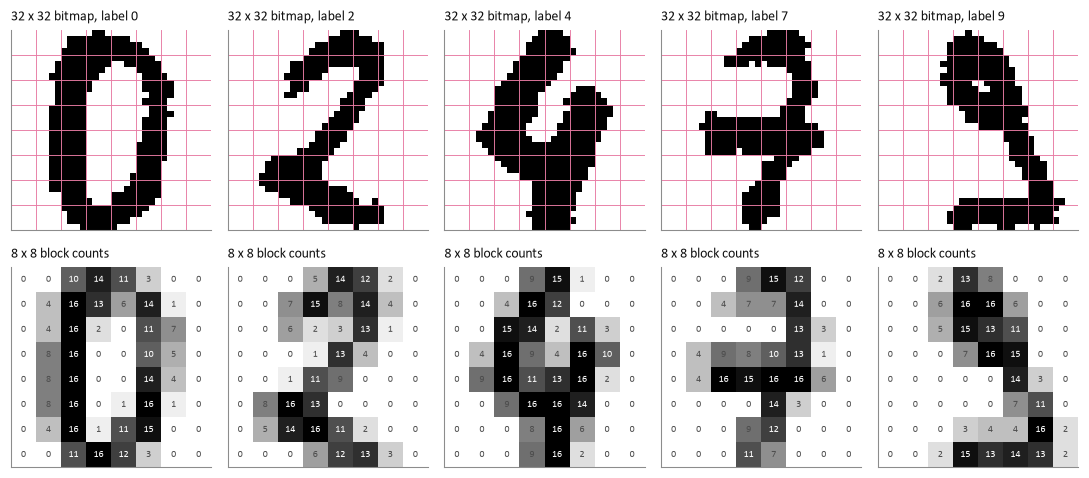

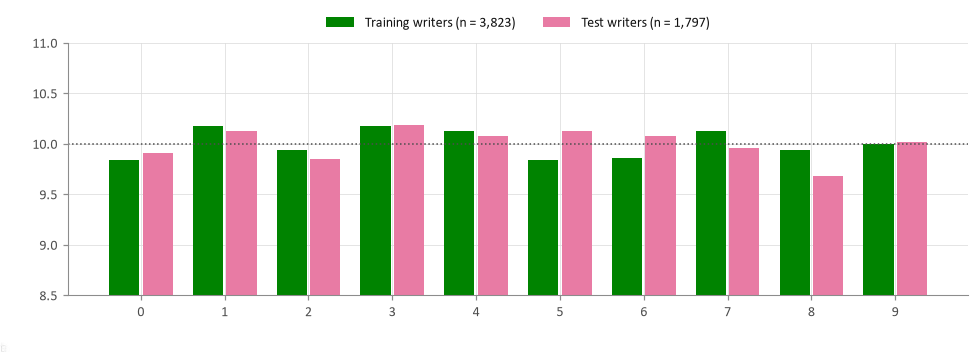

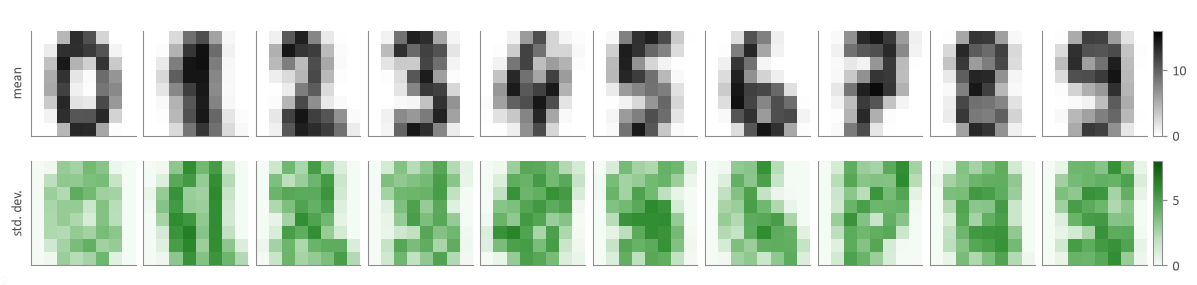

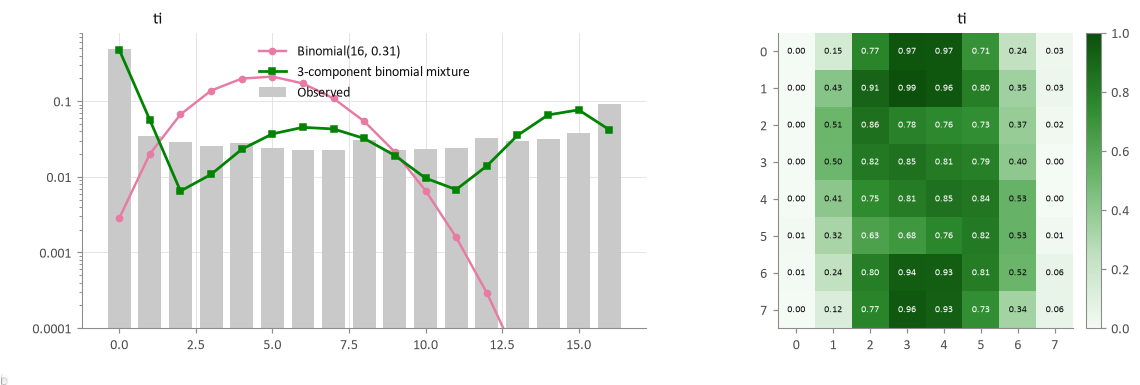

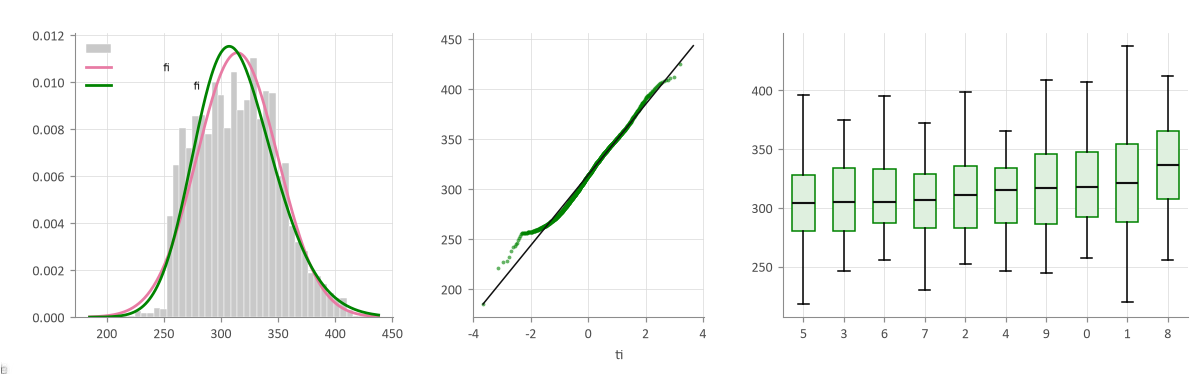

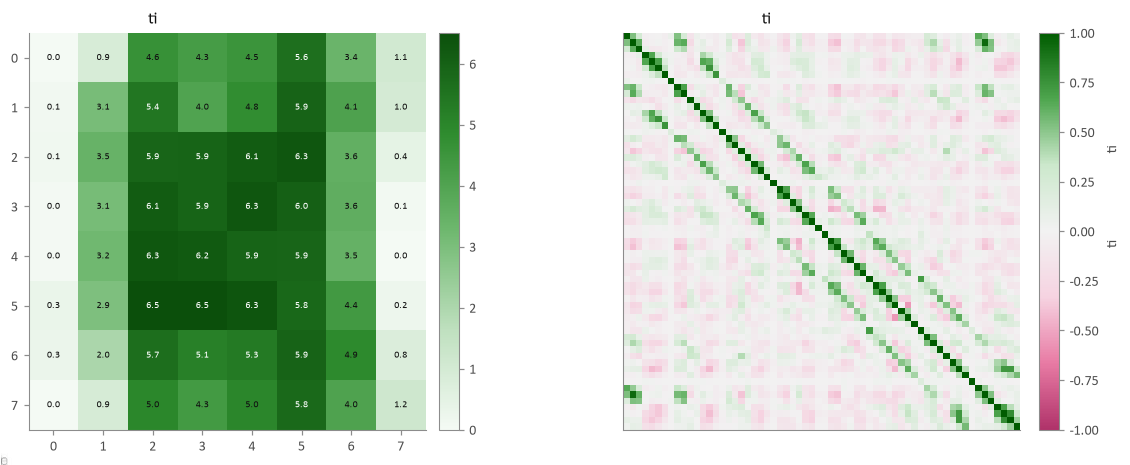

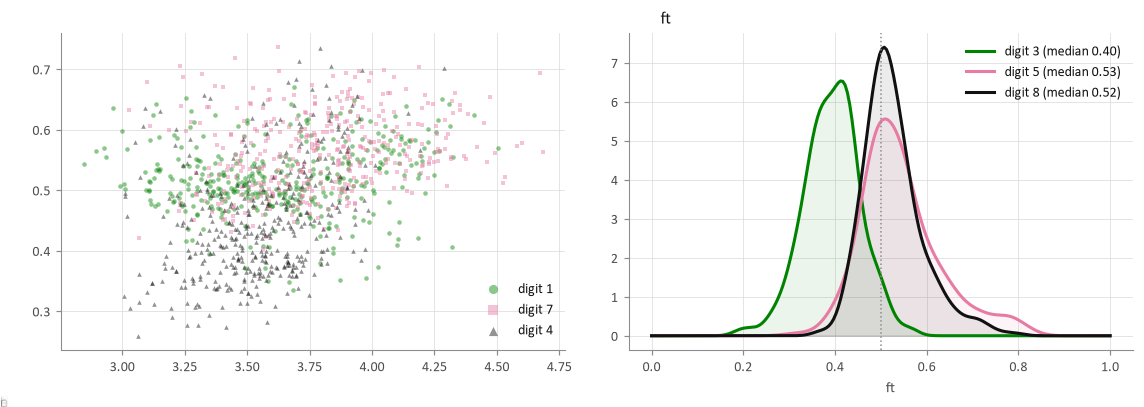

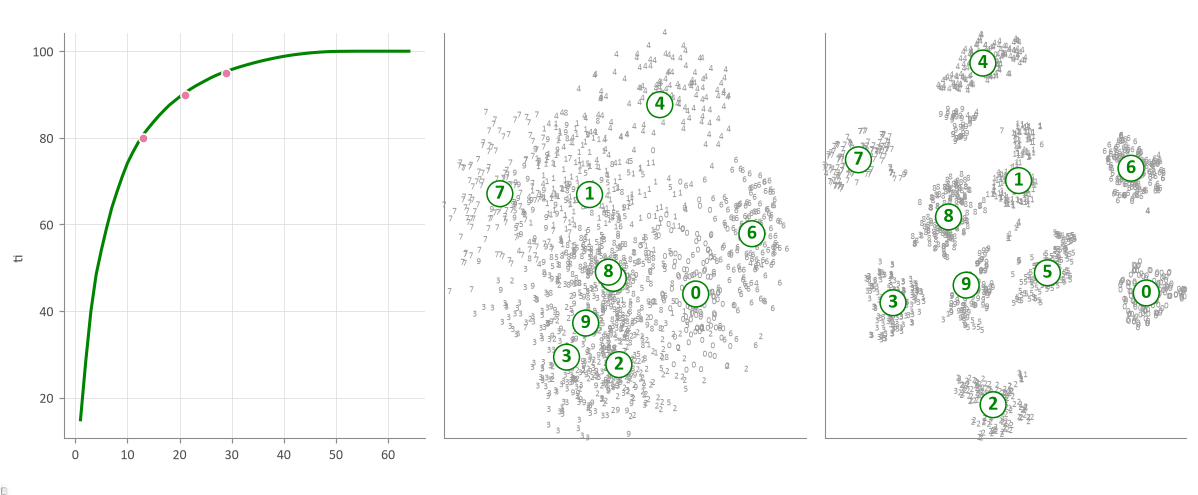

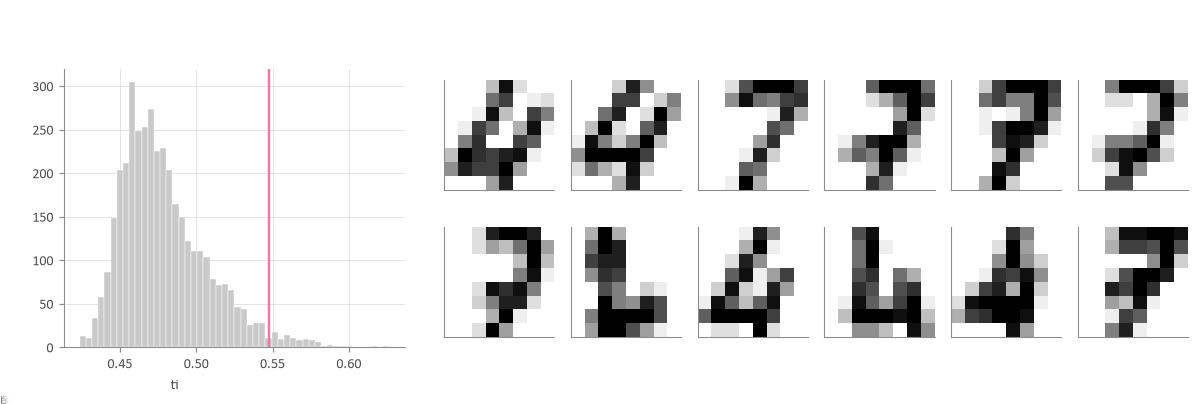

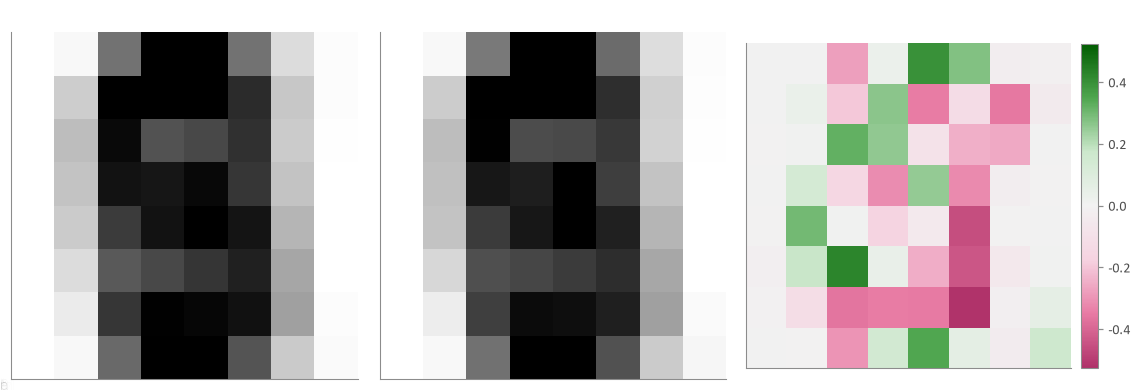

{'n_train': 3823, 'n_test': 1797, 'n_fields': 65, 'missing_cells': 0, 'out_of_range': 0, 'dup_rows_train': 0, 'dup_rows_test': 0, 'identical_images_train_and_test': 0, 'dup_images_with_conflicting_labels': 0, 'zero_variance_pixels': ['p00', 'p47'], 'near_constant_pixels': ['p00', 'p10', 'p20', 'p30', 'p37', 'p40', 'p47', 'p60', 'p70'], 'pixels_zero_pct': 48.84, 'pixels_sixteen_pct': 9.24, 'bitmap_to_table_exact_match_pct': 100.0, 'class_counts_train': [376, 389, 380, 389, 387, 376, 377, 387, 380, 382], 'class_counts_test': [178, 182, 177, 183, 181, 182, 181, 179, 174, 180], 'chisq_uniform_train': [np.float64(0.66), np.float64(0.9999)], 'chisq_uniform_test': [np.float64(0.38), np.float64(1.0)], 'chisq_train_vs_test': [np.float64(0.3), np.float64(1.0)], 'binomial_p': 0.307, 'aic_binomial': 5061904.7, 'aic_mixture3': 1574236.2, 'mixture3_weights': [0.5364, 0.227, 0.2366], 'mixture3_p': [0.0072, 0.3997, 0.8975], 'ink': {'mean': 314.3, 'sd': 35.4, 'min': 185, 'max': 438, 'skew': 0.243, 'kur

In [3]:
%run step2_explore.py

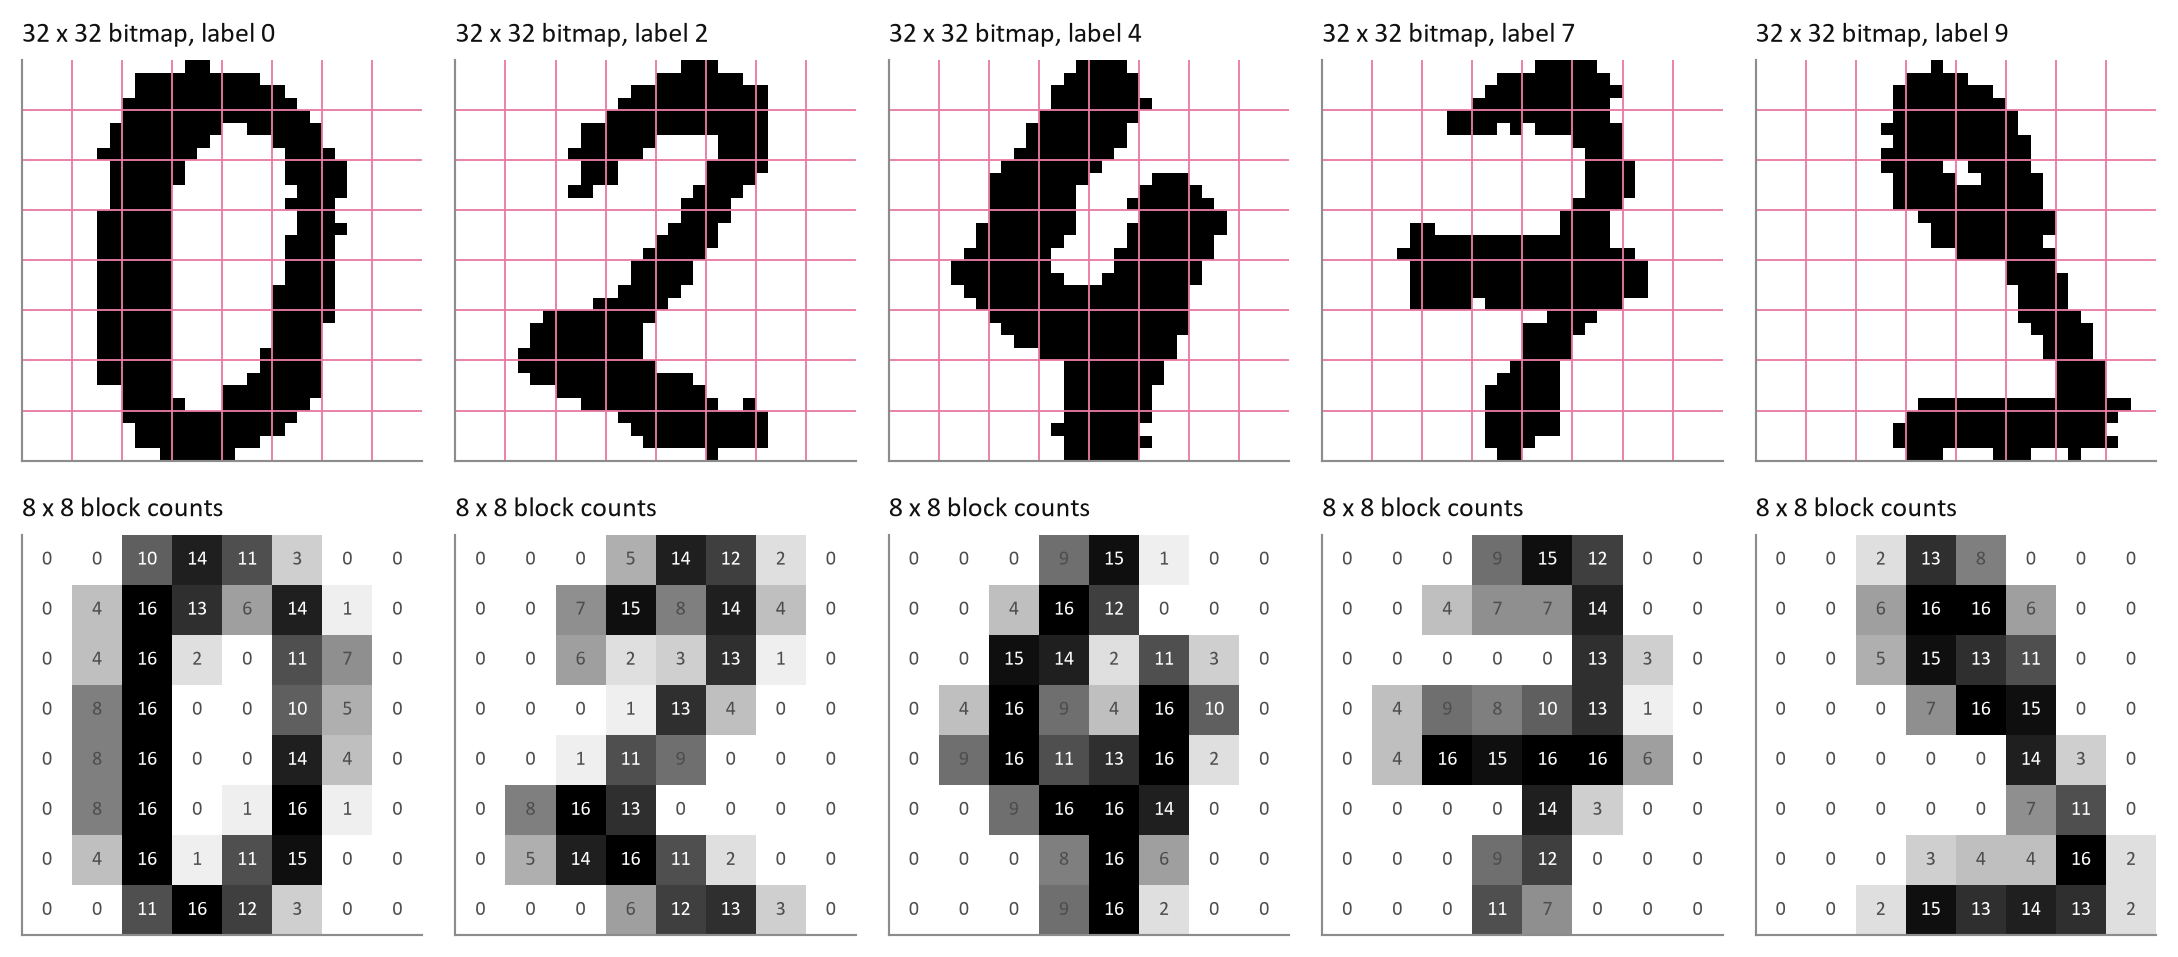

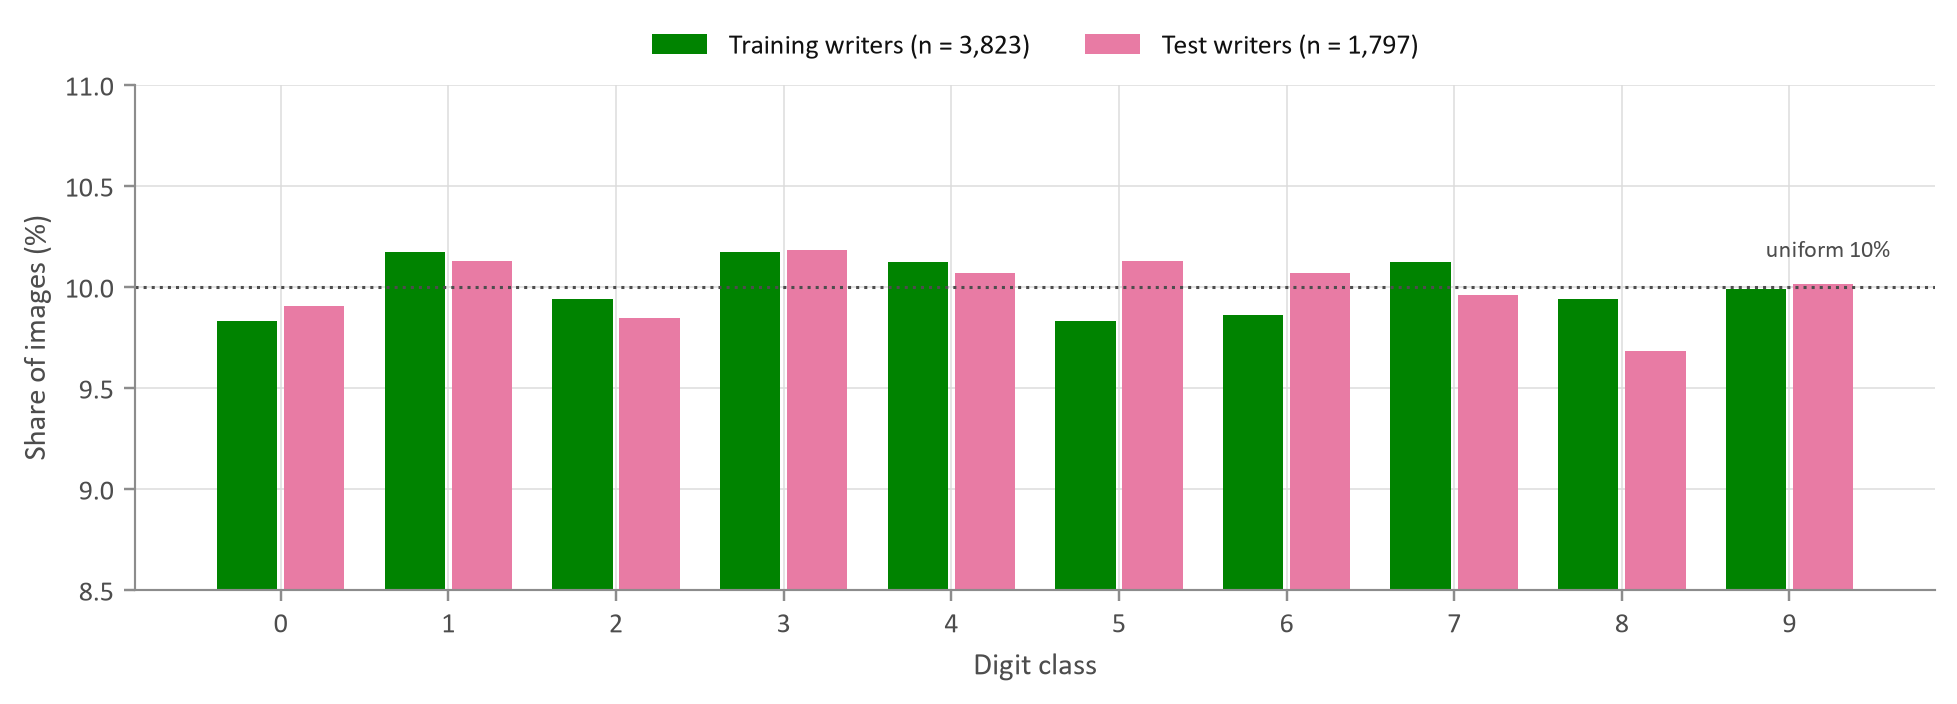

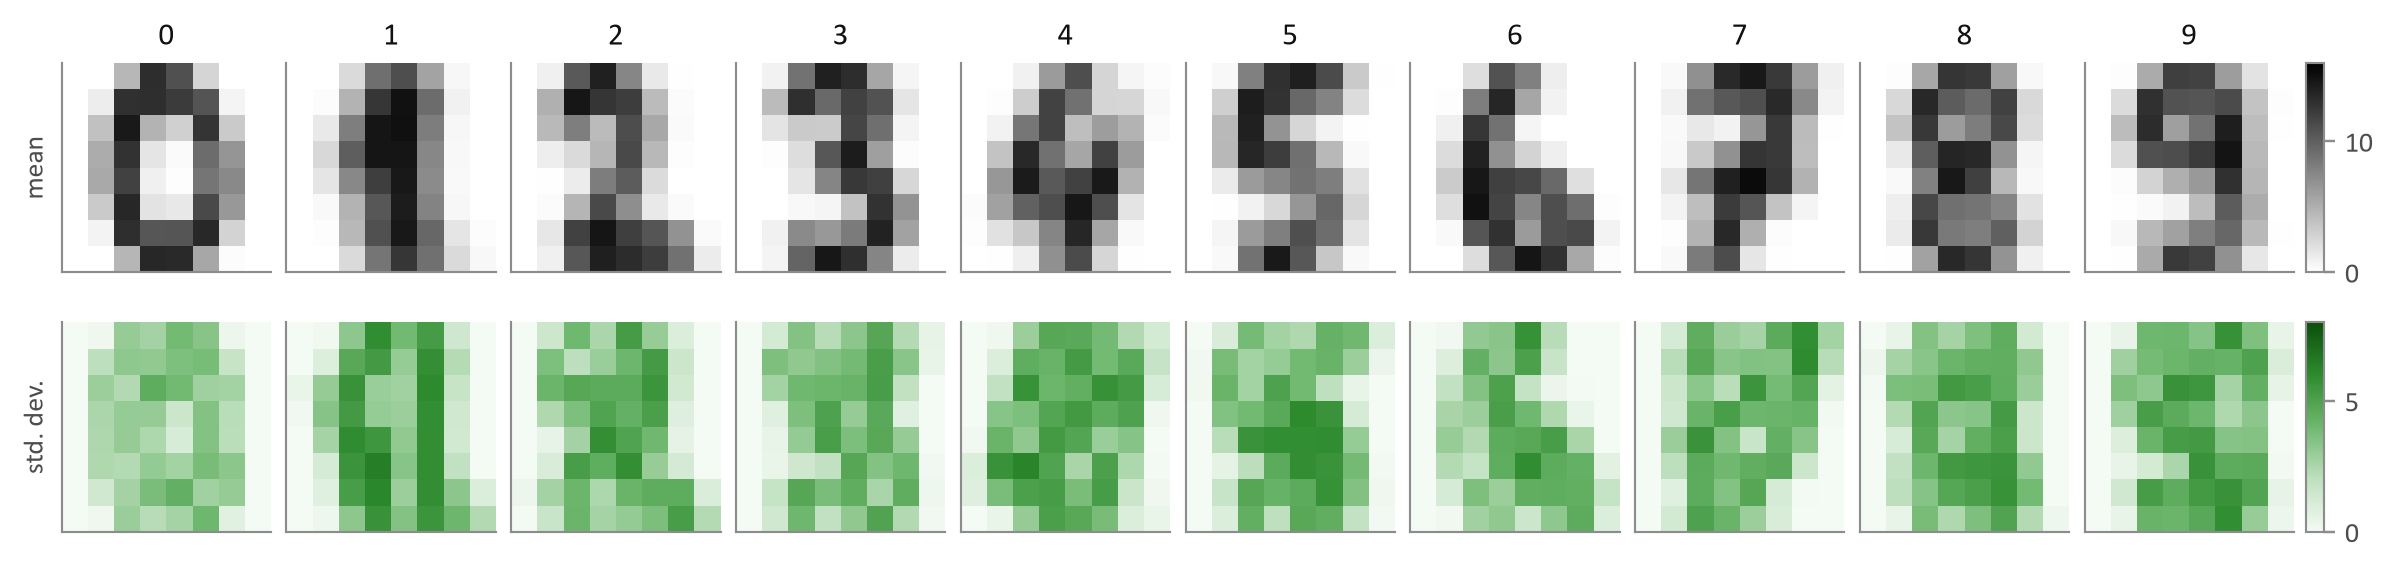

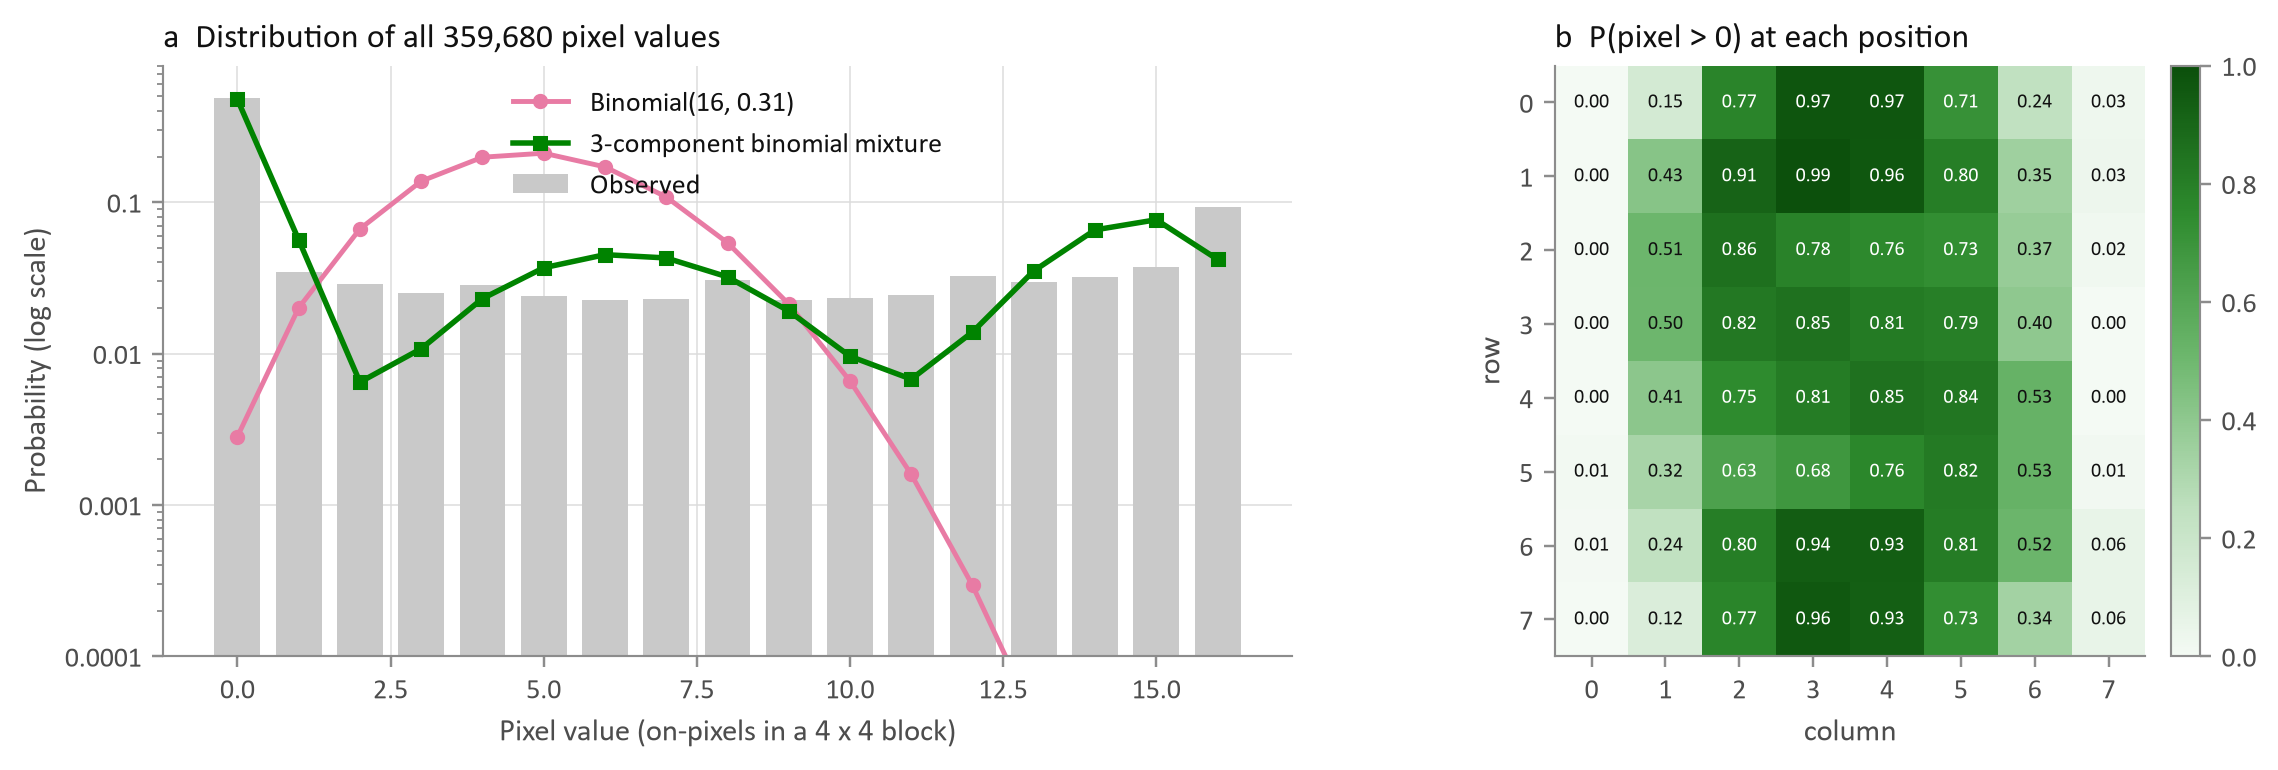

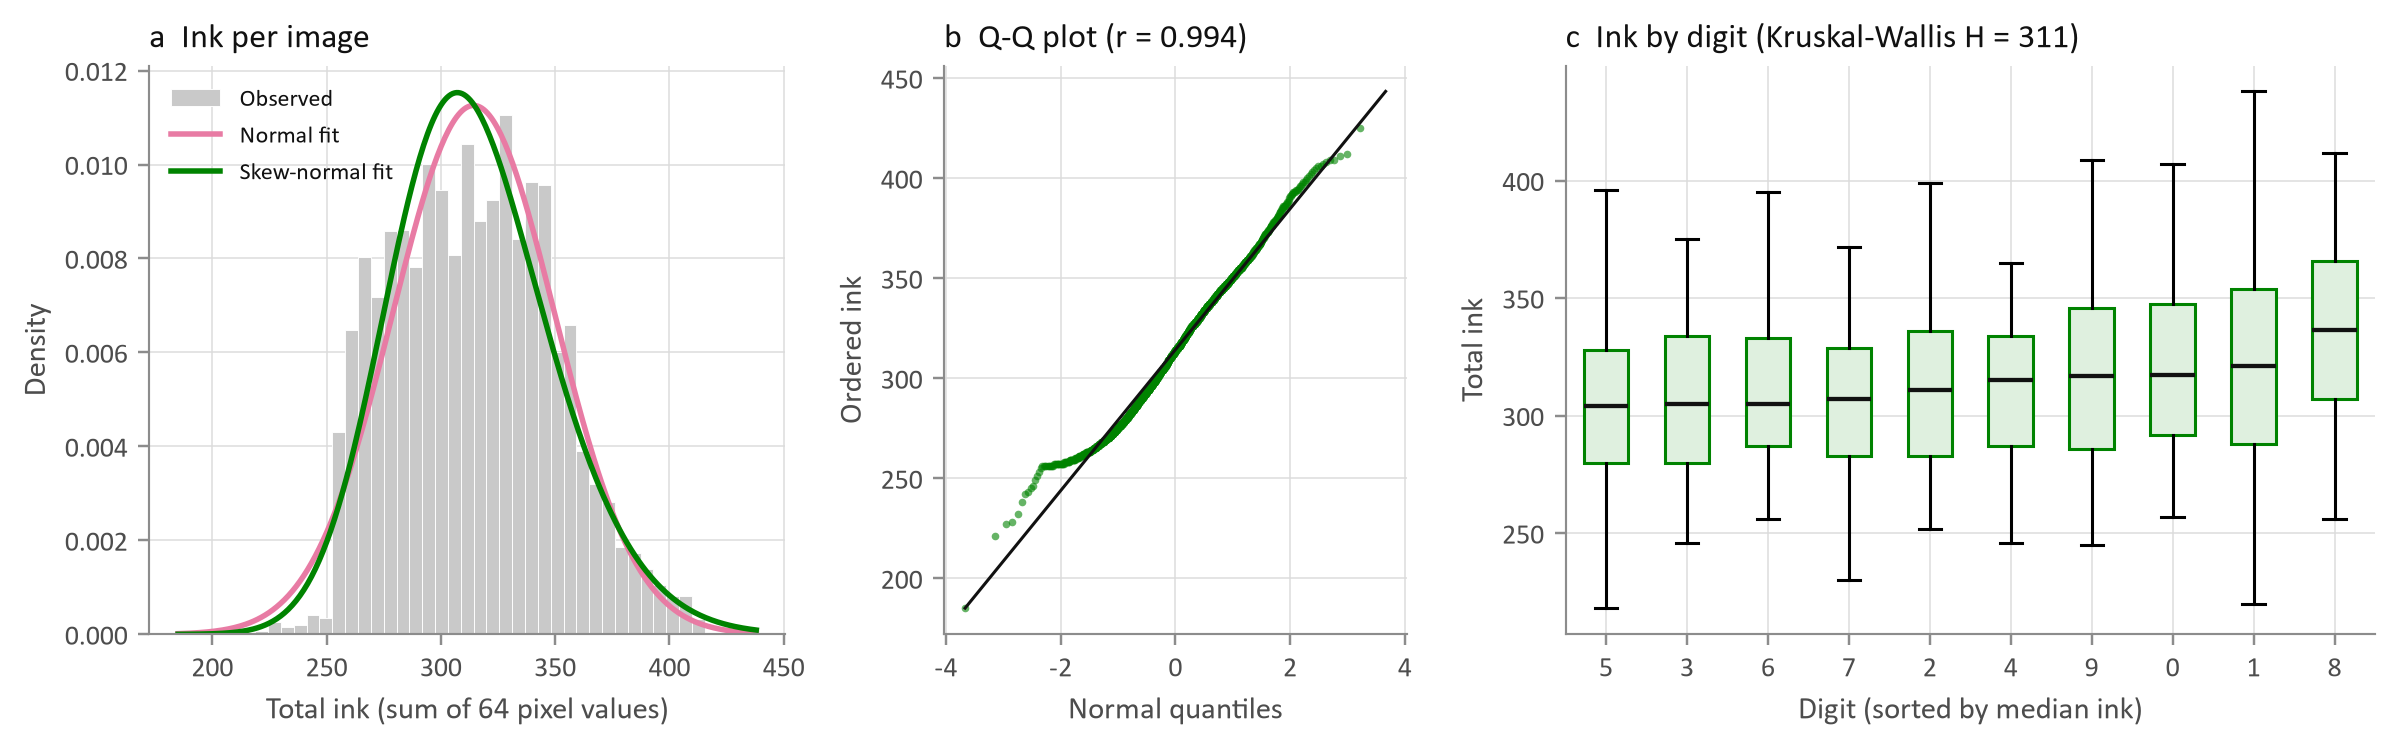

In [4]:
show('d01_bitmap_to_features', 'd02_class_balance', 'd03_class_mean_std', 'd04_pixel_distribution', 'd05_ink_distribution')

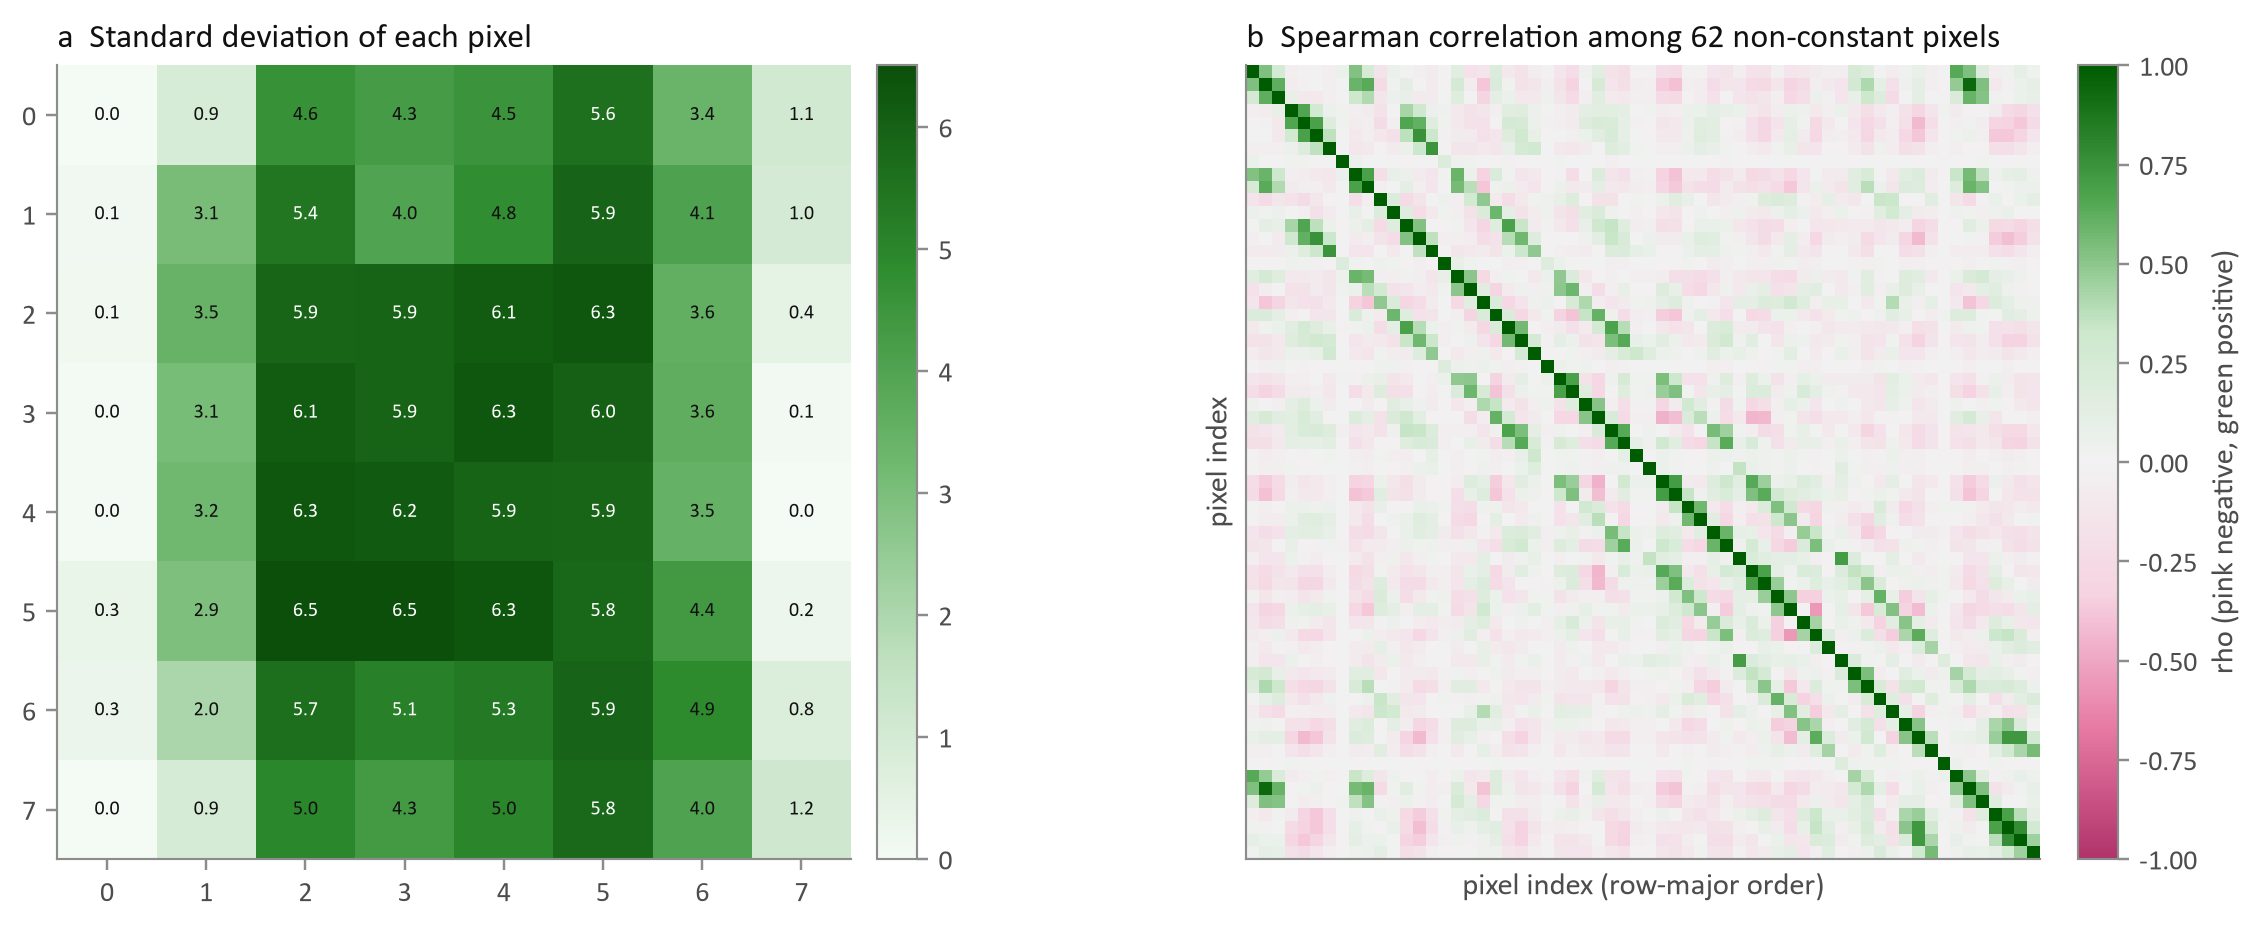

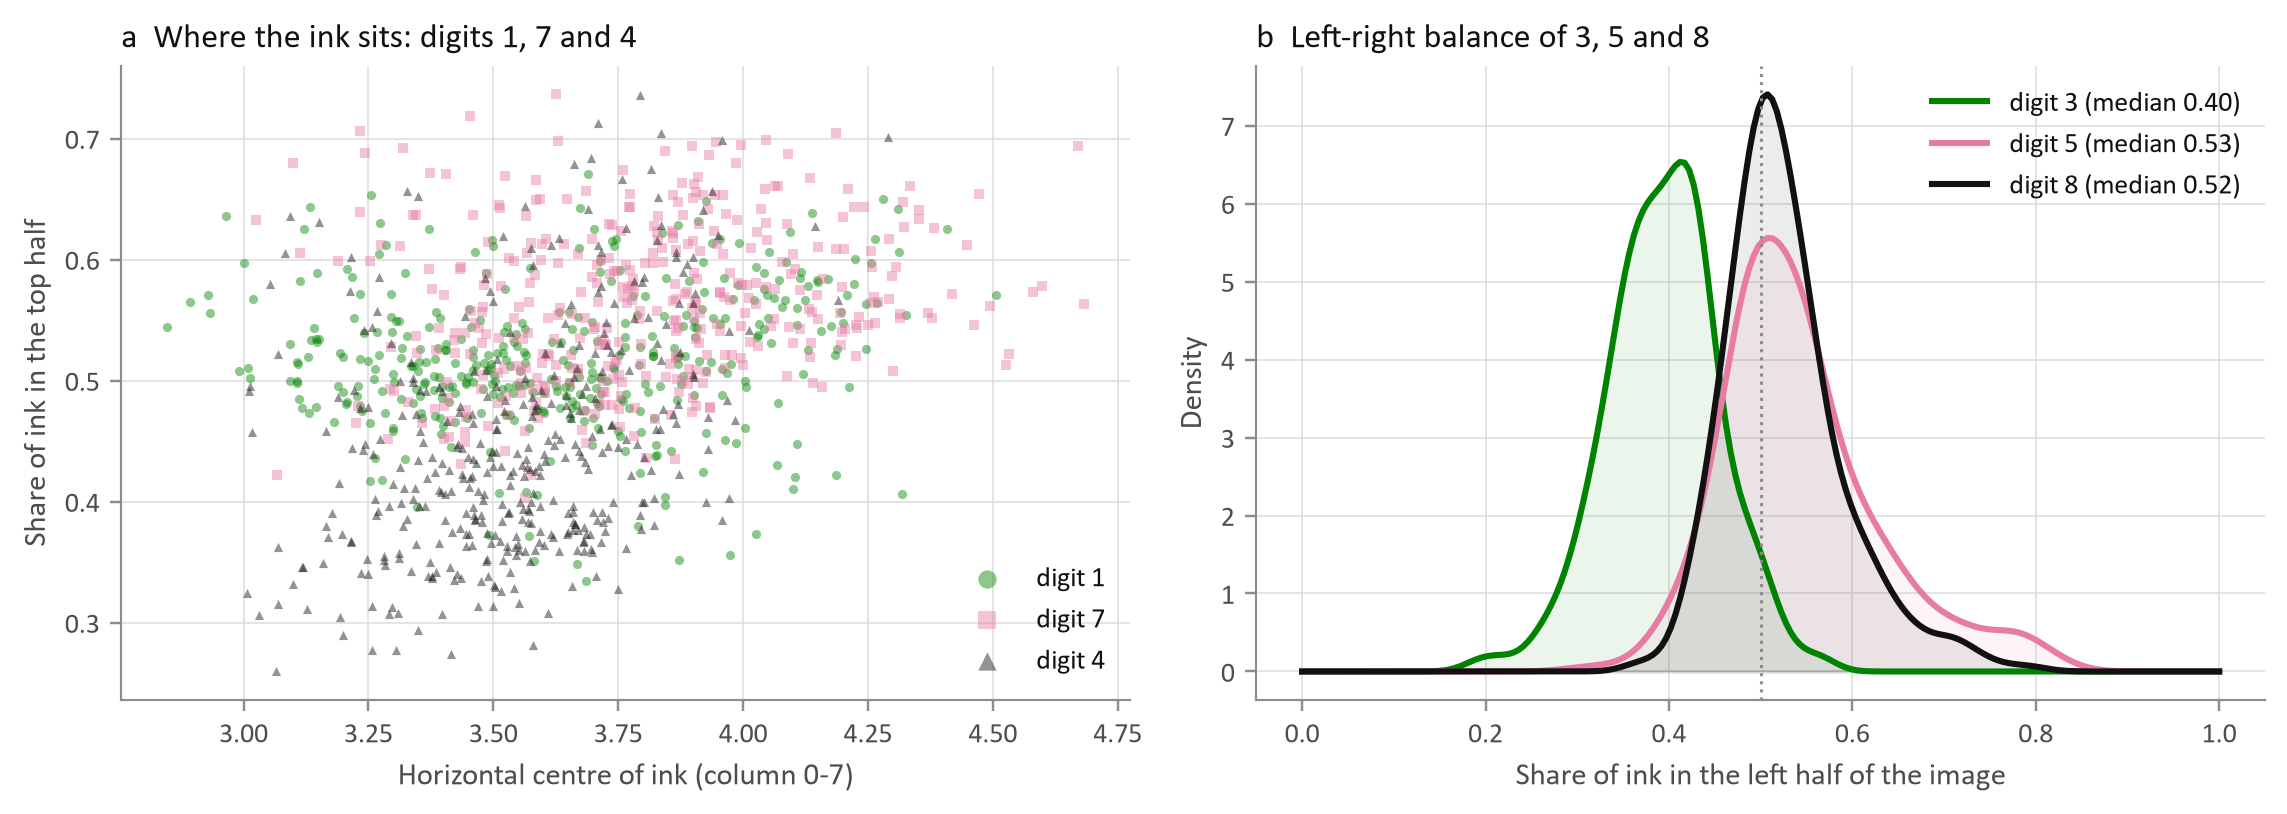

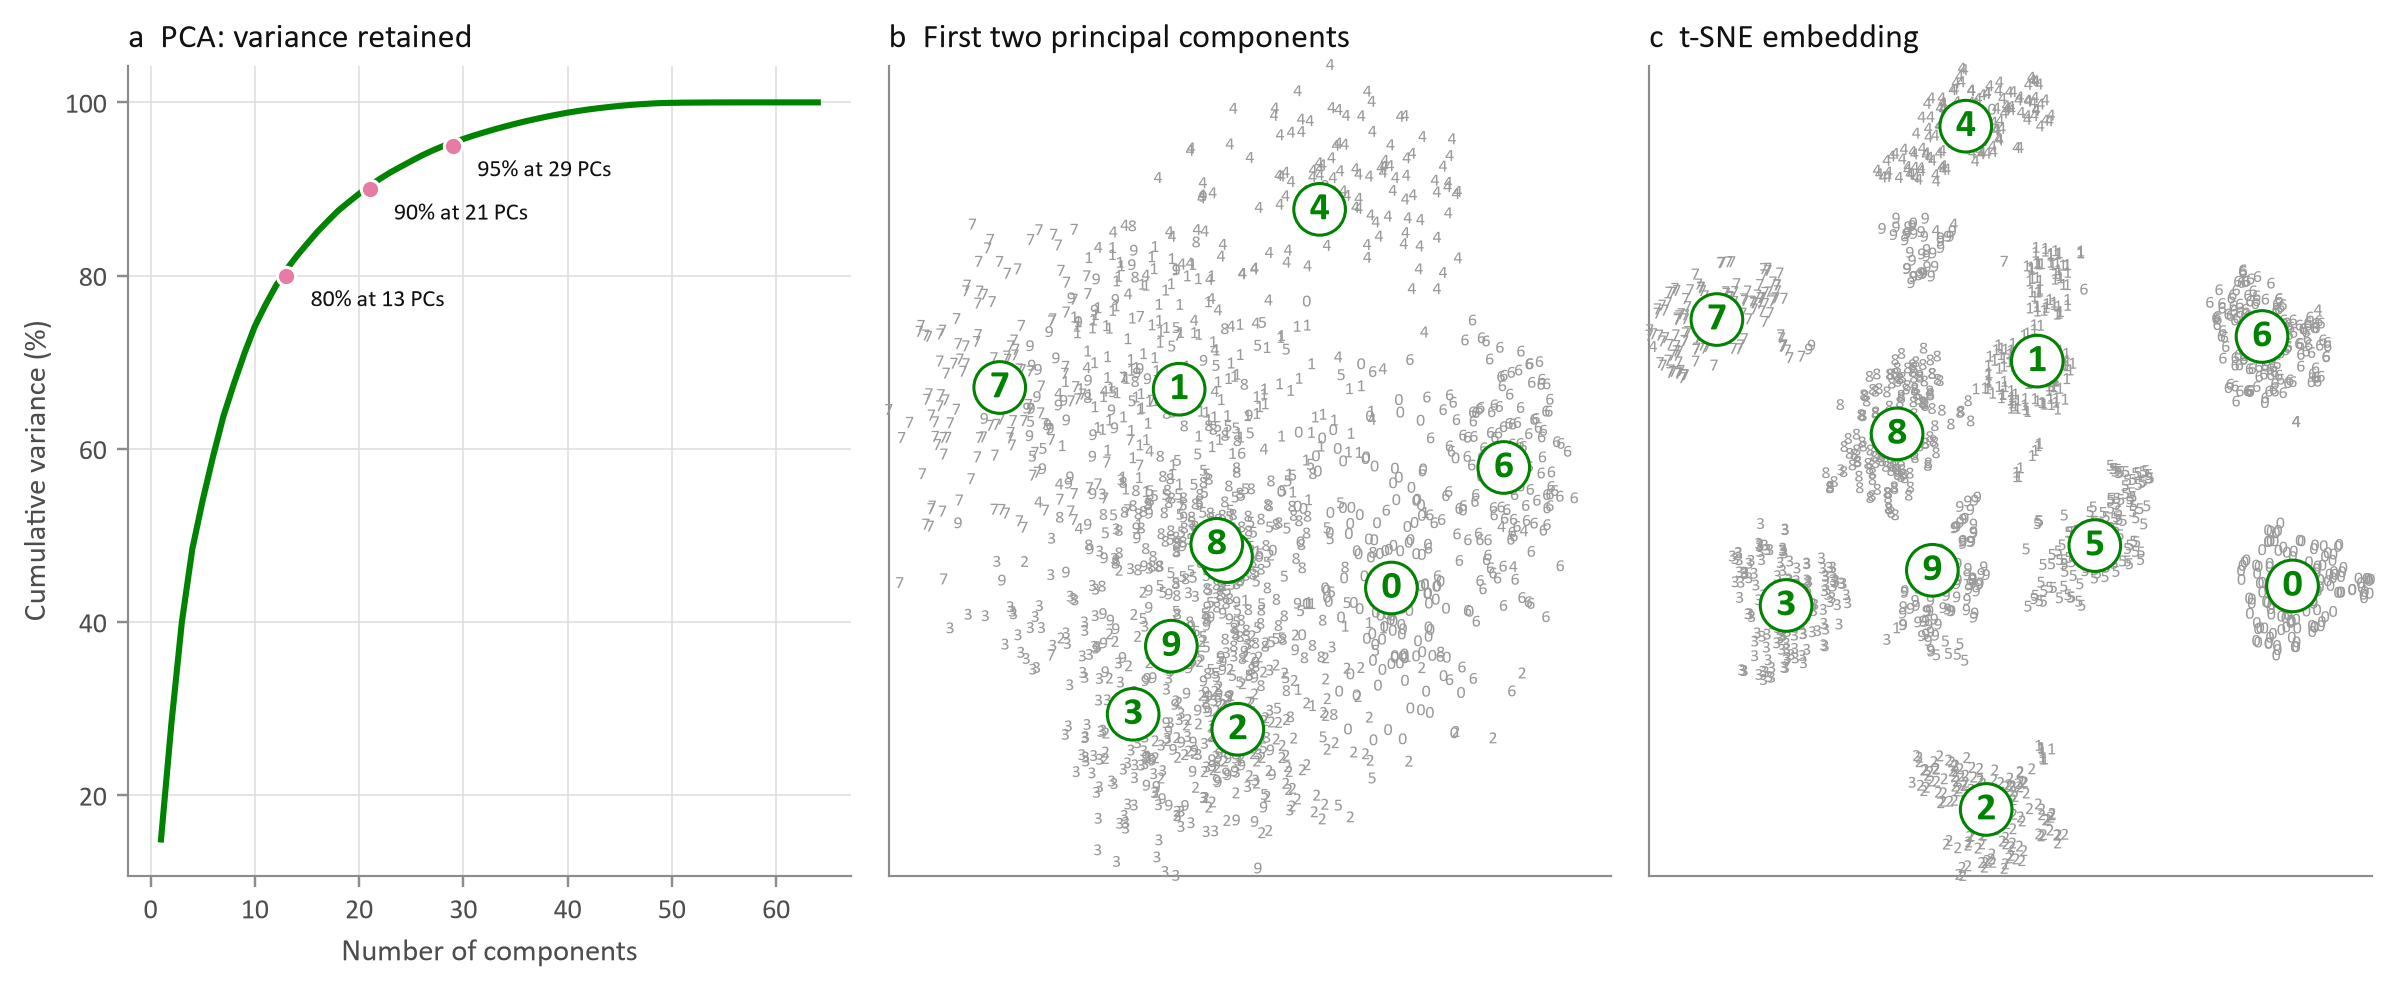

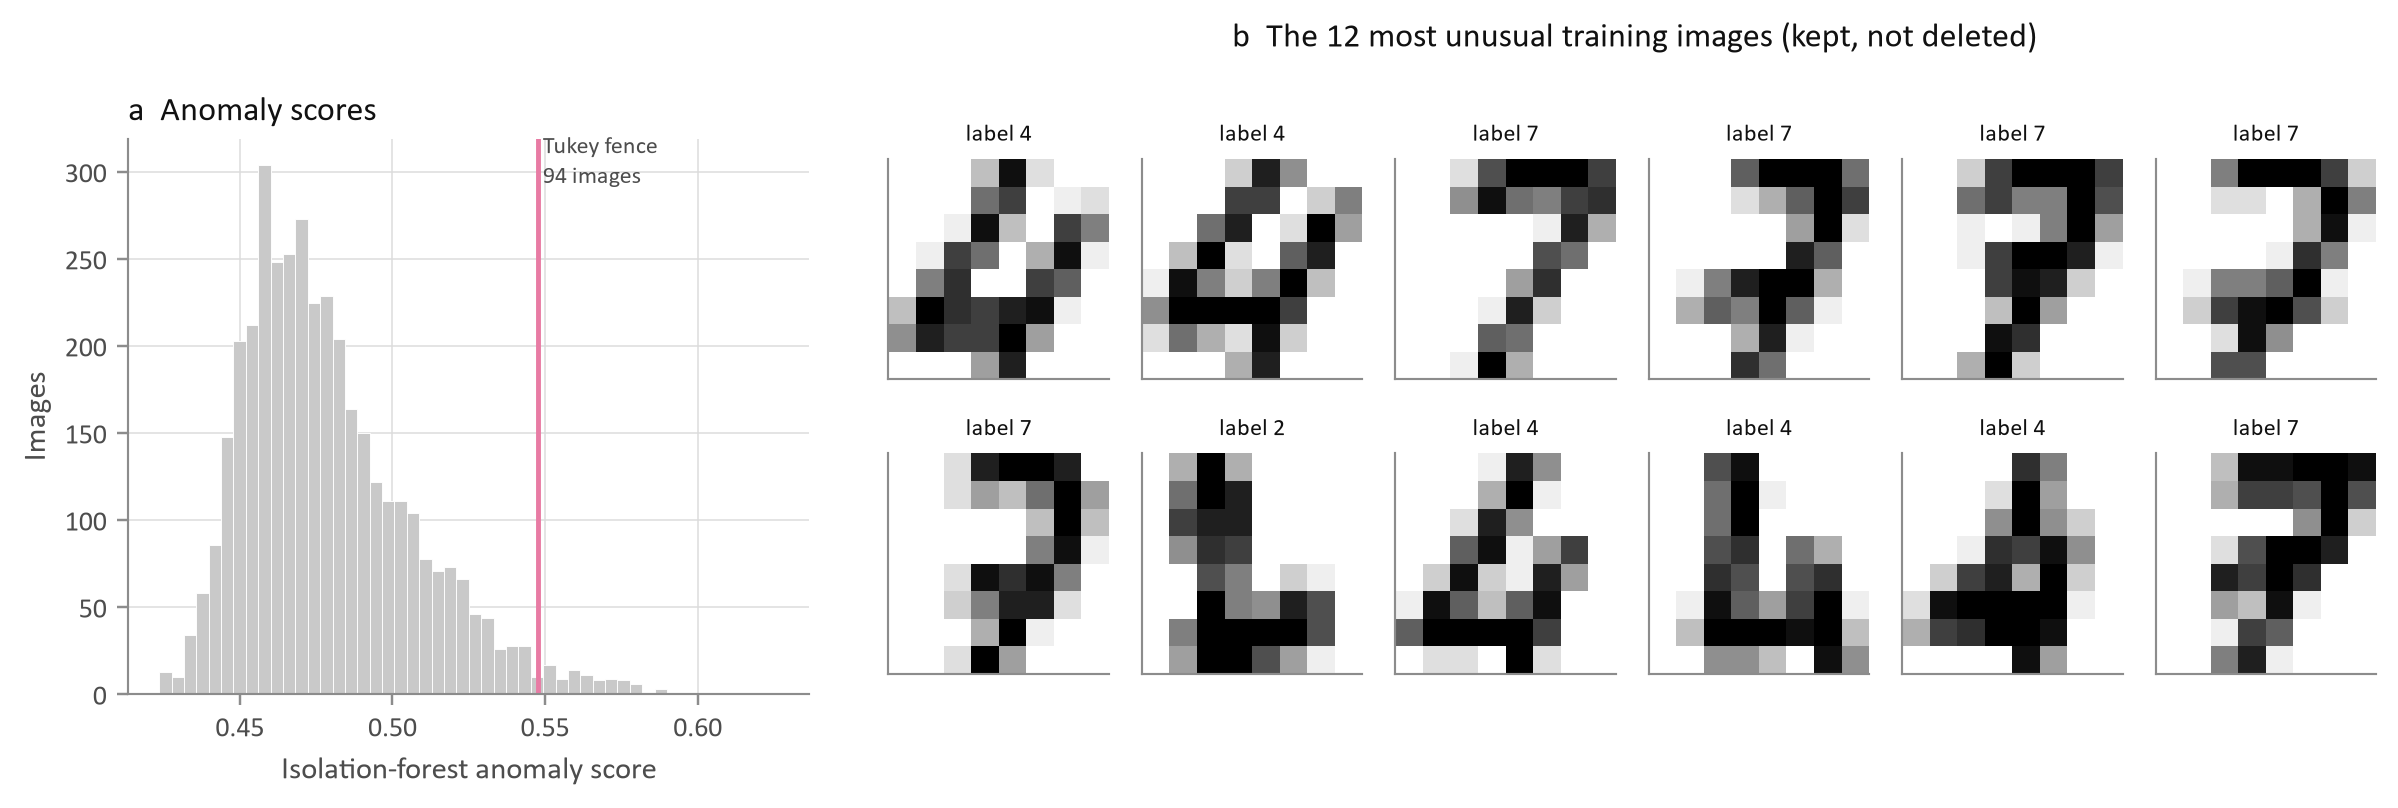

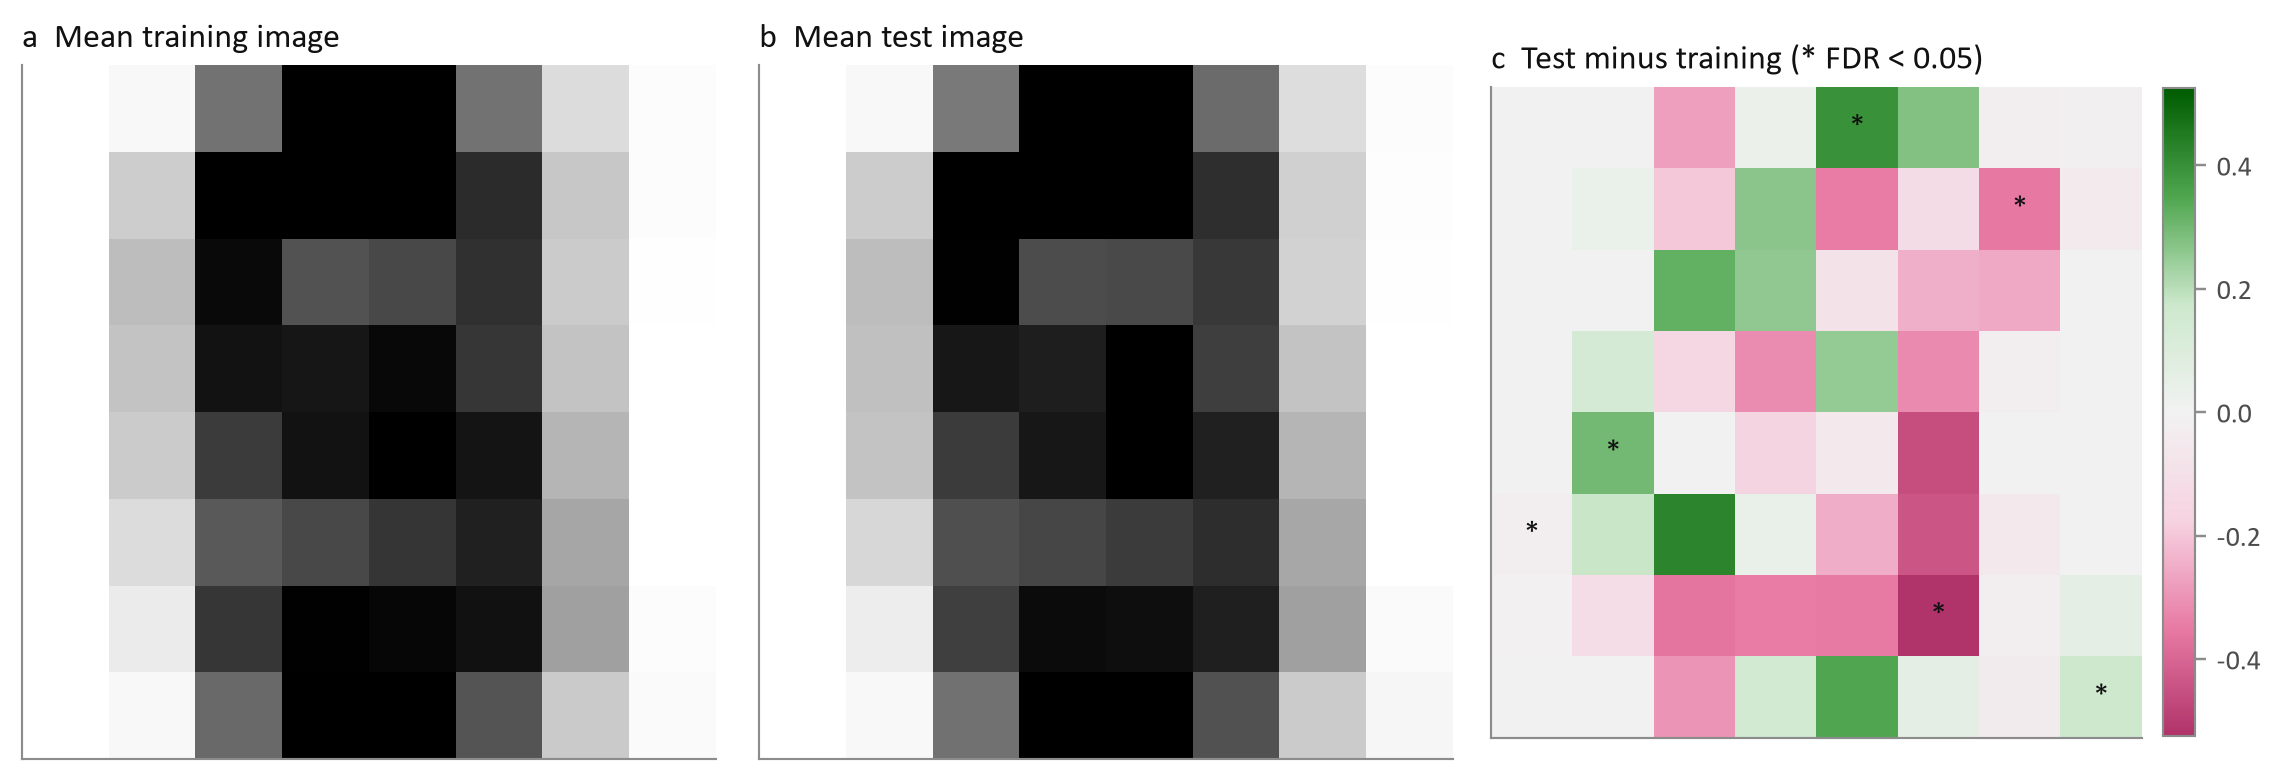

In [5]:
show('d06_variability_correlation', 'd07_shape_features', 'd08_pca_tsne', 'd09_outliers', 'd10_writer_shift')

## 3. Deep learning model: CNN with a small hyper-parameter grid
The 3,823 training images are split 85 / 15 into training and validation sets. The 1,797 test images come from 13 different writers and are used only in step 4.

{'config': 1, 'filters': '16-32', 'dropout': 0.25, 'augment': False, 'epochs': 33, 'best_epoch': 21, 'val_acc': 0.9895, 'val_loss': 0.0303, 'params': 16218}


{'config': 2, 'filters': '16-32', 'dropout': 0.25, 'augment': True, 'epochs': 37, 'best_epoch': 25, 'val_acc': 0.9808, 'val_loss': 0.0476, 'params': 16218}


{'config': 3, 'filters': '16-32', 'dropout': 0.5, 'augment': False, 'epochs': 34, 'best_epoch': 22, 'val_acc': 0.9895, 'val_loss': 0.0343, 'params': 16218}


{'config': 4, 'filters': '16-32', 'dropout': 0.5, 'augment': True, 'epochs': 37, 'best_epoch': 25, 'val_acc': 0.9808, 'val_loss': 0.0549, 'params': 16218}


{'config': 5, 'filters': '32-64', 'dropout': 0.25, 'augment': False, 'epochs': 31, 'best_epoch': 19, 'val_acc': 0.9913, 'val_loss': 0.0272, 'params': 45546}


{'config': 6, 'filters': '32-64', 'dropout': 0.25, 'augment': True, 'epochs': 49, 'best_epoch': 37, 'val_acc': 0.993, 'val_loss': 0.0143, 'params': 45546}


{'config': 7, 'filters': '32-64', 'dropout': 0.5, 'augment': False, 'epochs': 42, 'best_epoch': 30, 'val_acc': 0.9913, 'val_loss': 0.029, 'params': 45546}


{'config': 8, 'filters': '32-64', 'dropout': 0.5, 'augment': True, 'epochs': 39, 'best_epoch': 27, 'val_acc': 0.993, 'val_loss': 0.0297, 'params': 45546}


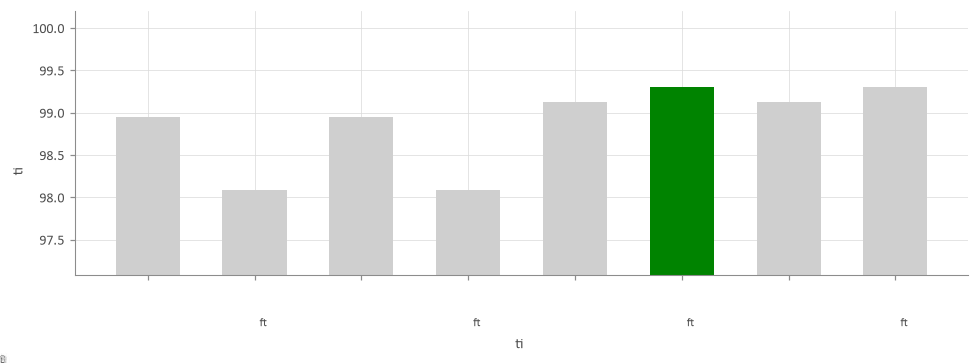

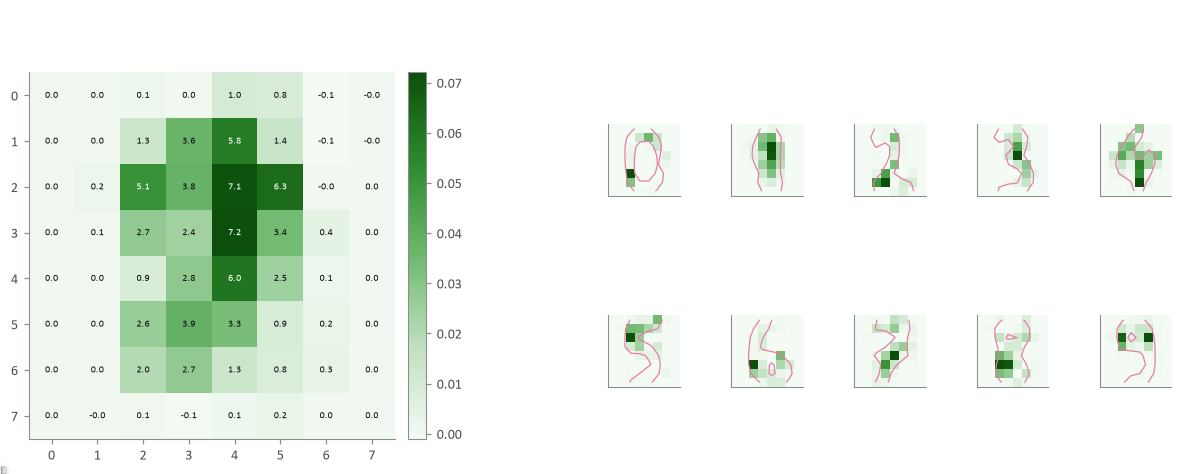

best {'config': 6, 'filters': '32-64', 'dropout': 0.25, 'augment': True, 'epochs': 49, 'best_epoch': 37, 'val_acc': 0.993, 'val_loss': 0.0143, 'params': 45546} knn {1: 0.9860627177700348, 3: 0.9878048780487805, 5: 0.9843205574912892, 7: 0.9843205574912892}


In [6]:
%run step3_train_cnn.py

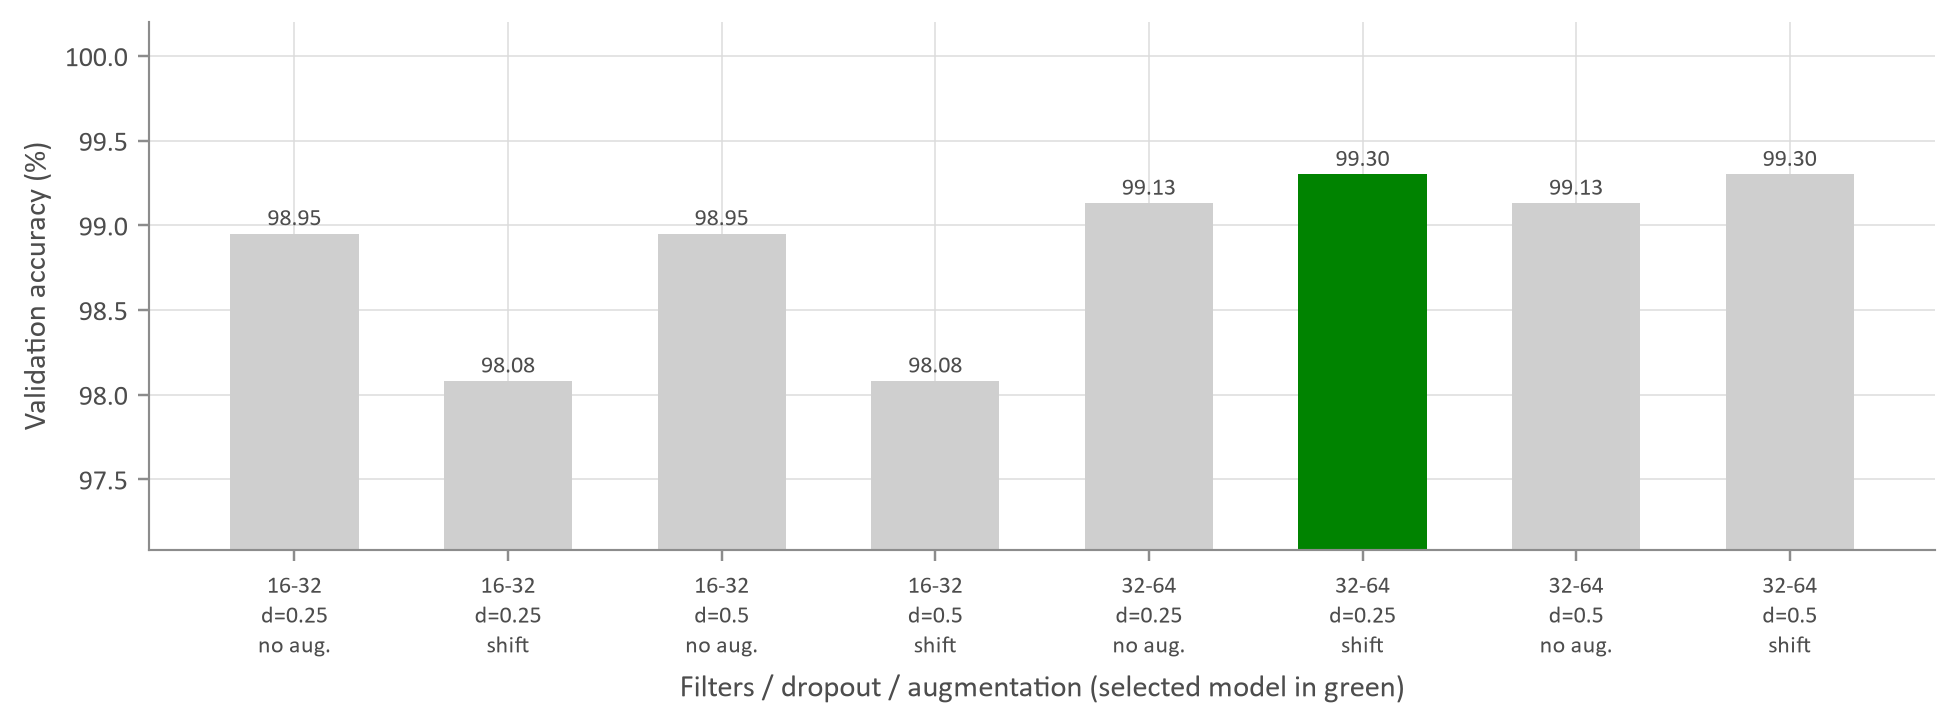

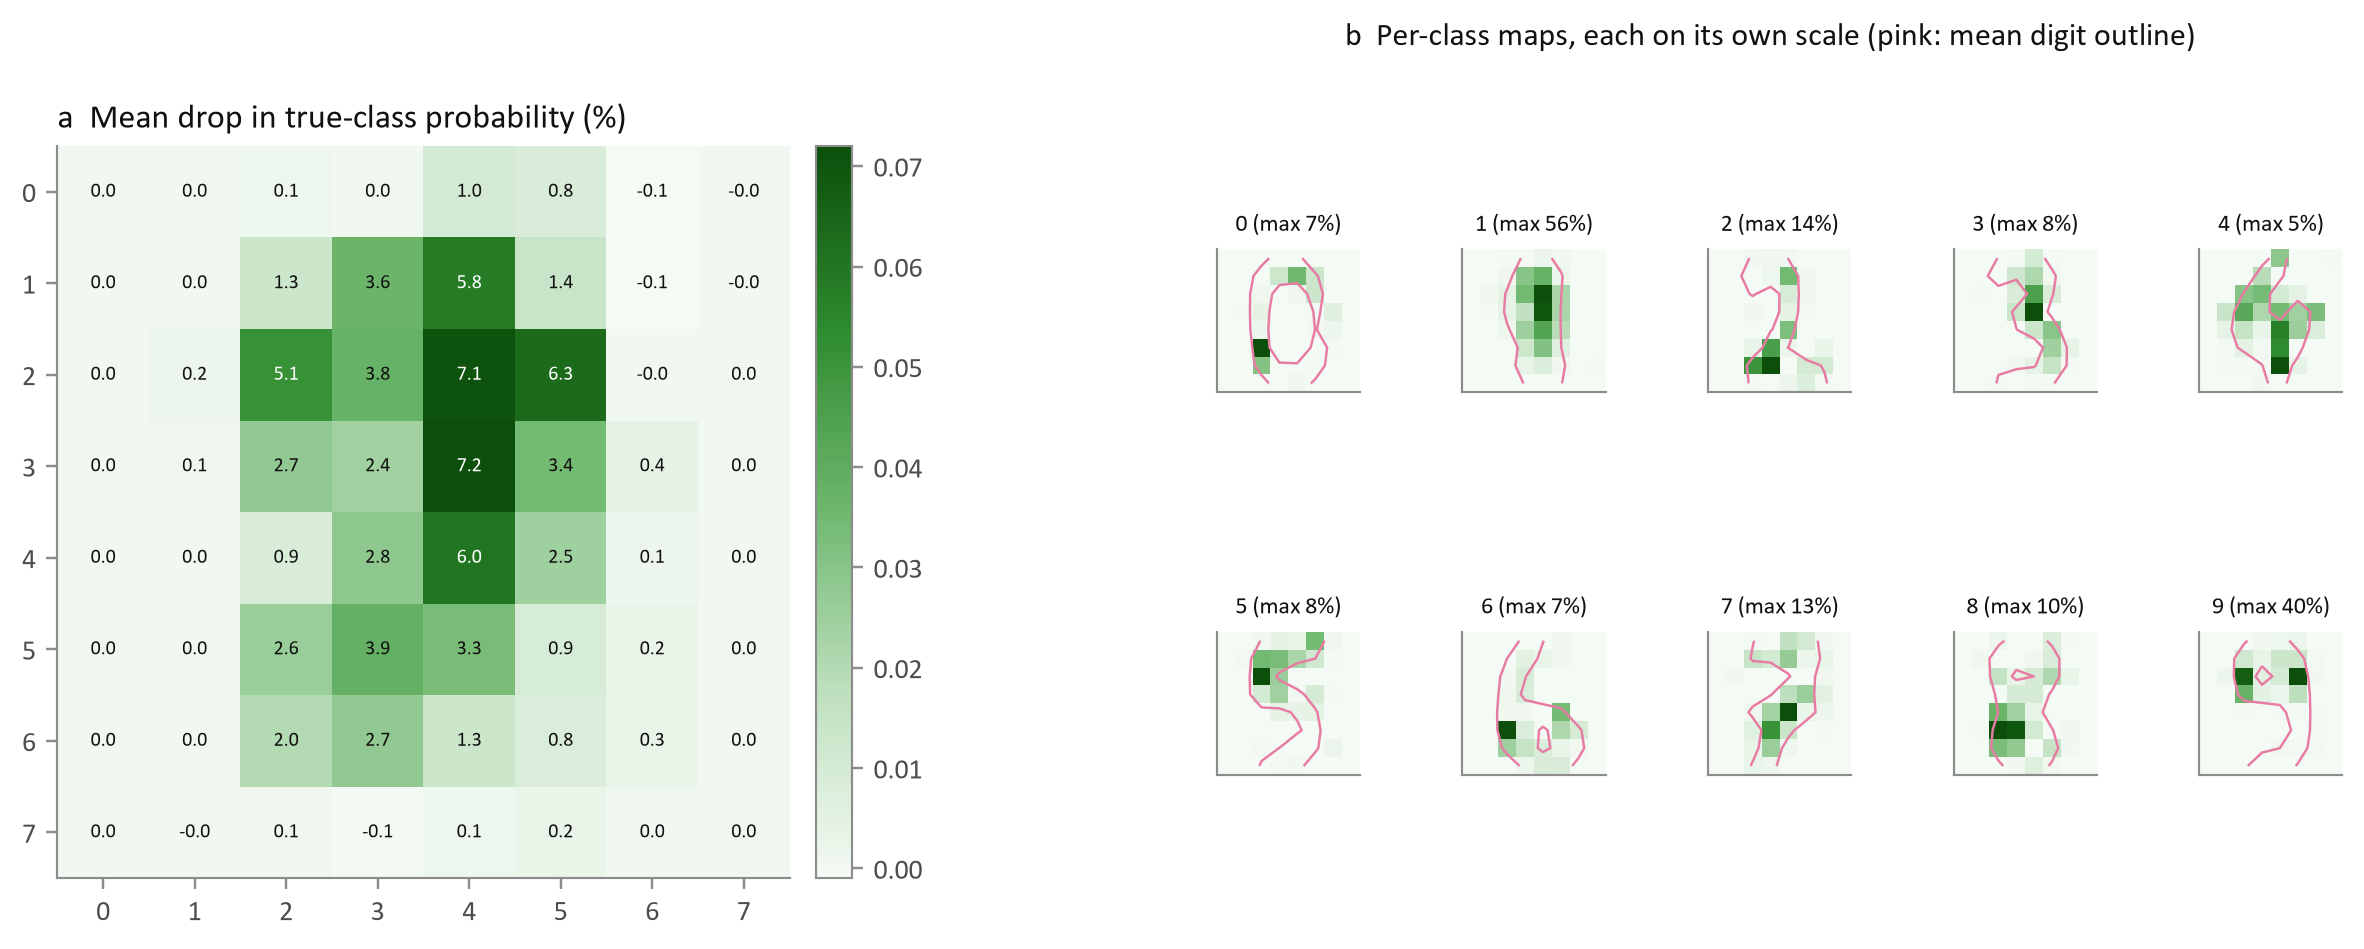

In [7]:
show('m01_tuning', 'm02_occlusion')

## 4. Result visualization on the writer-independent test set

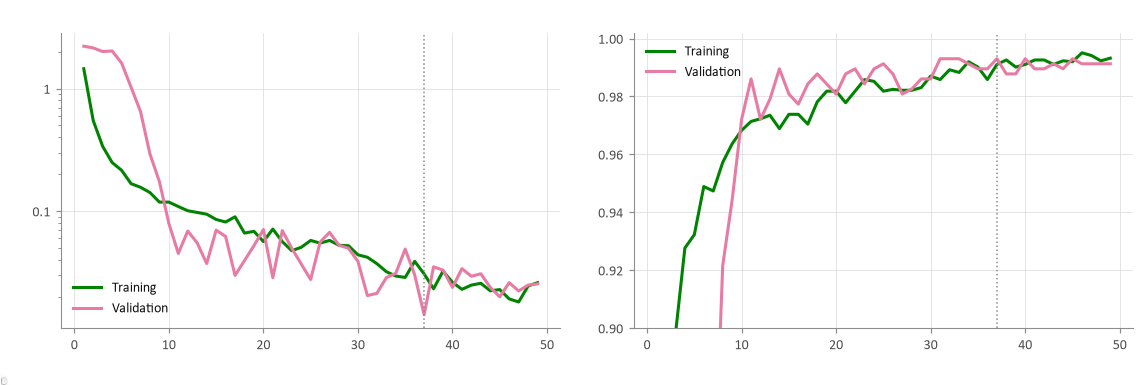

C:\Users\nakul\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


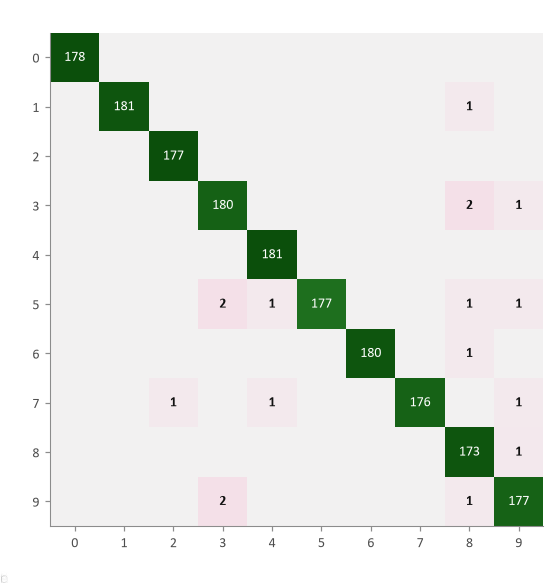

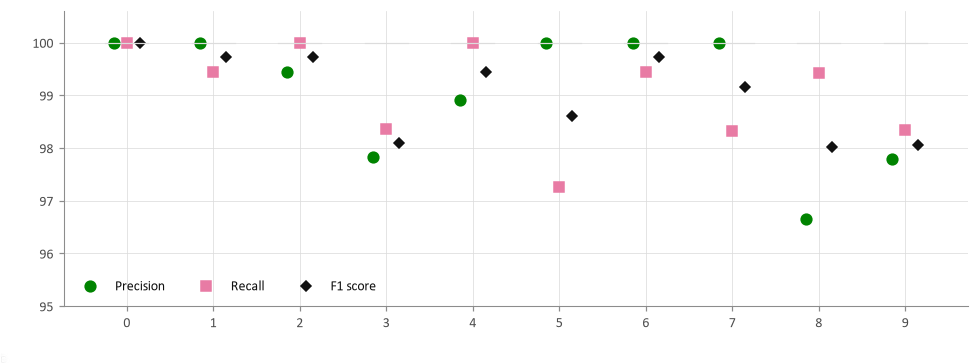

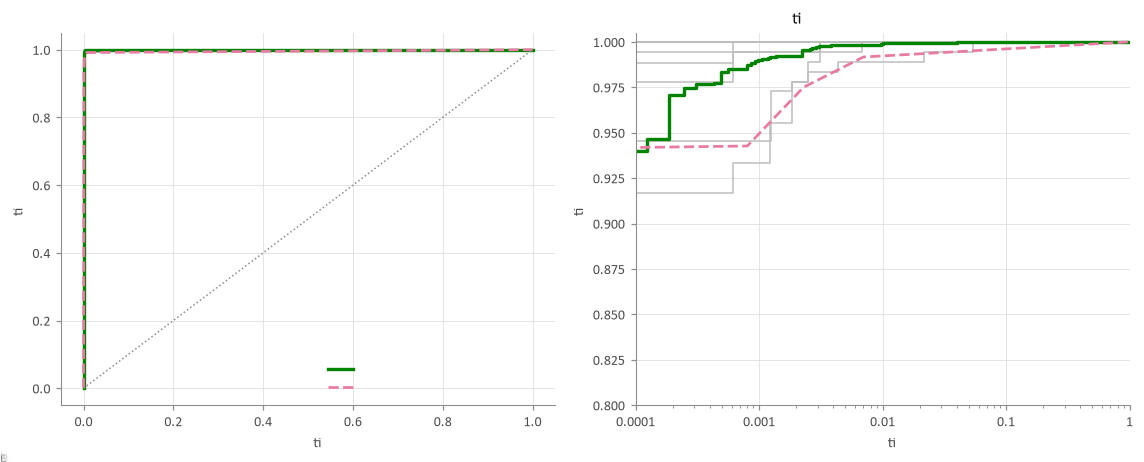

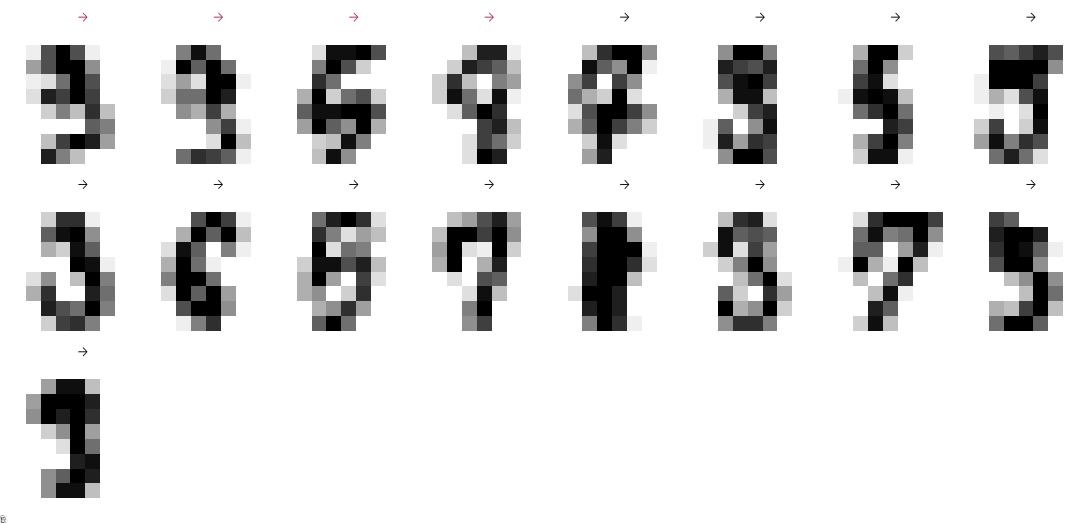

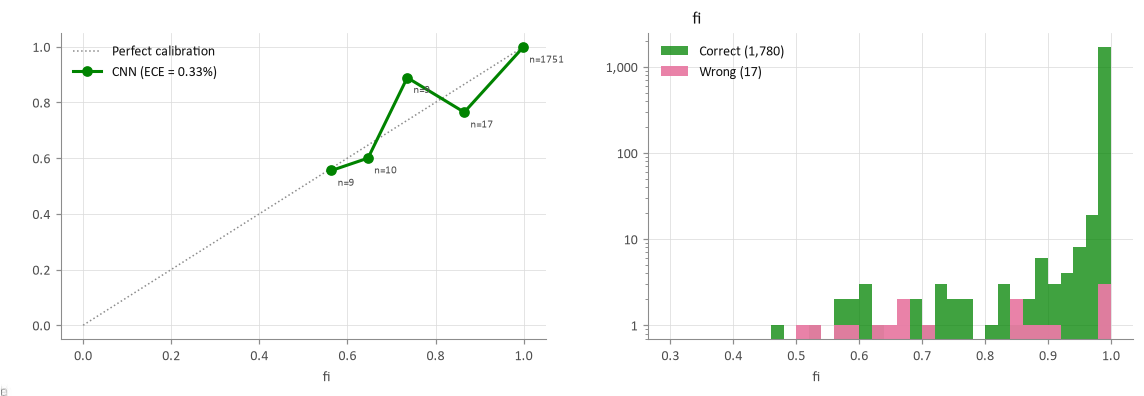

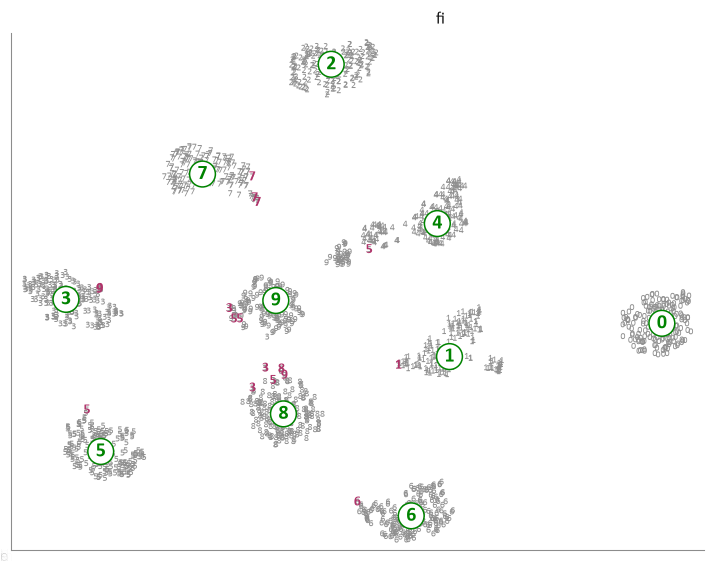

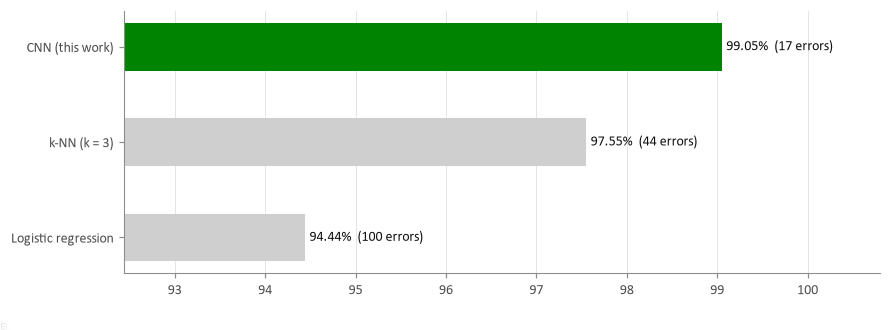

{
 "cnn": {
  "accuracy": 0.9905,
  "macro_f1": 0.9905,
  "kappa": 0.9895,
  "log_loss": 0.0304,
  "macro_auc": 0.99993,
  "errors": 17,
  "acc_ci95": [
   0.9849,
   0.9941
  ]
 },
 "knn": {
  "accuracy": 0.9755,
  "macro_f1": 0.9756,
  "kappa": 0.9728,
  "log_loss": 0.166,
  "macro_auc": 0.99523,
  "errors": 44
 },
 "logreg": {
  "accuracy": 0.9444,
  "macro_f1": 0.9446,
  "kappa": 0.9382,
  "log_loss": 0.1728,
  "macro_auc": 0.99836,
  "errors": 100
 },
 "mcnemar_cnn_vs_knn": {
  "cnn_right_knn_wrong": 37,
  "cnn_wrong_knn_right": 10,
  "p_value": 9.848878492846323e-05
 },
 "ece": 0.0033,
 "n_errors": 17,
 "confusion_top": [
  {
   "true": 9,
   "pred": 3,
   "n": 2
  },
  {
   "true": 5,
   "pred": 3,
   "n": 2
  },
  {
   "true": 3,
   "pred": 8,
   "n": 2
  },
  {
   "true": 9,
   "pred": 8,
   "n": 1
  },
  {
   "true": 8,
   "pred": 9,
   "n": 1
  },
  {
   "true": 7,
   "pred": 9,
   "n": 1
  }
 ]
}


In [8]:
%run step4_evaluate.py

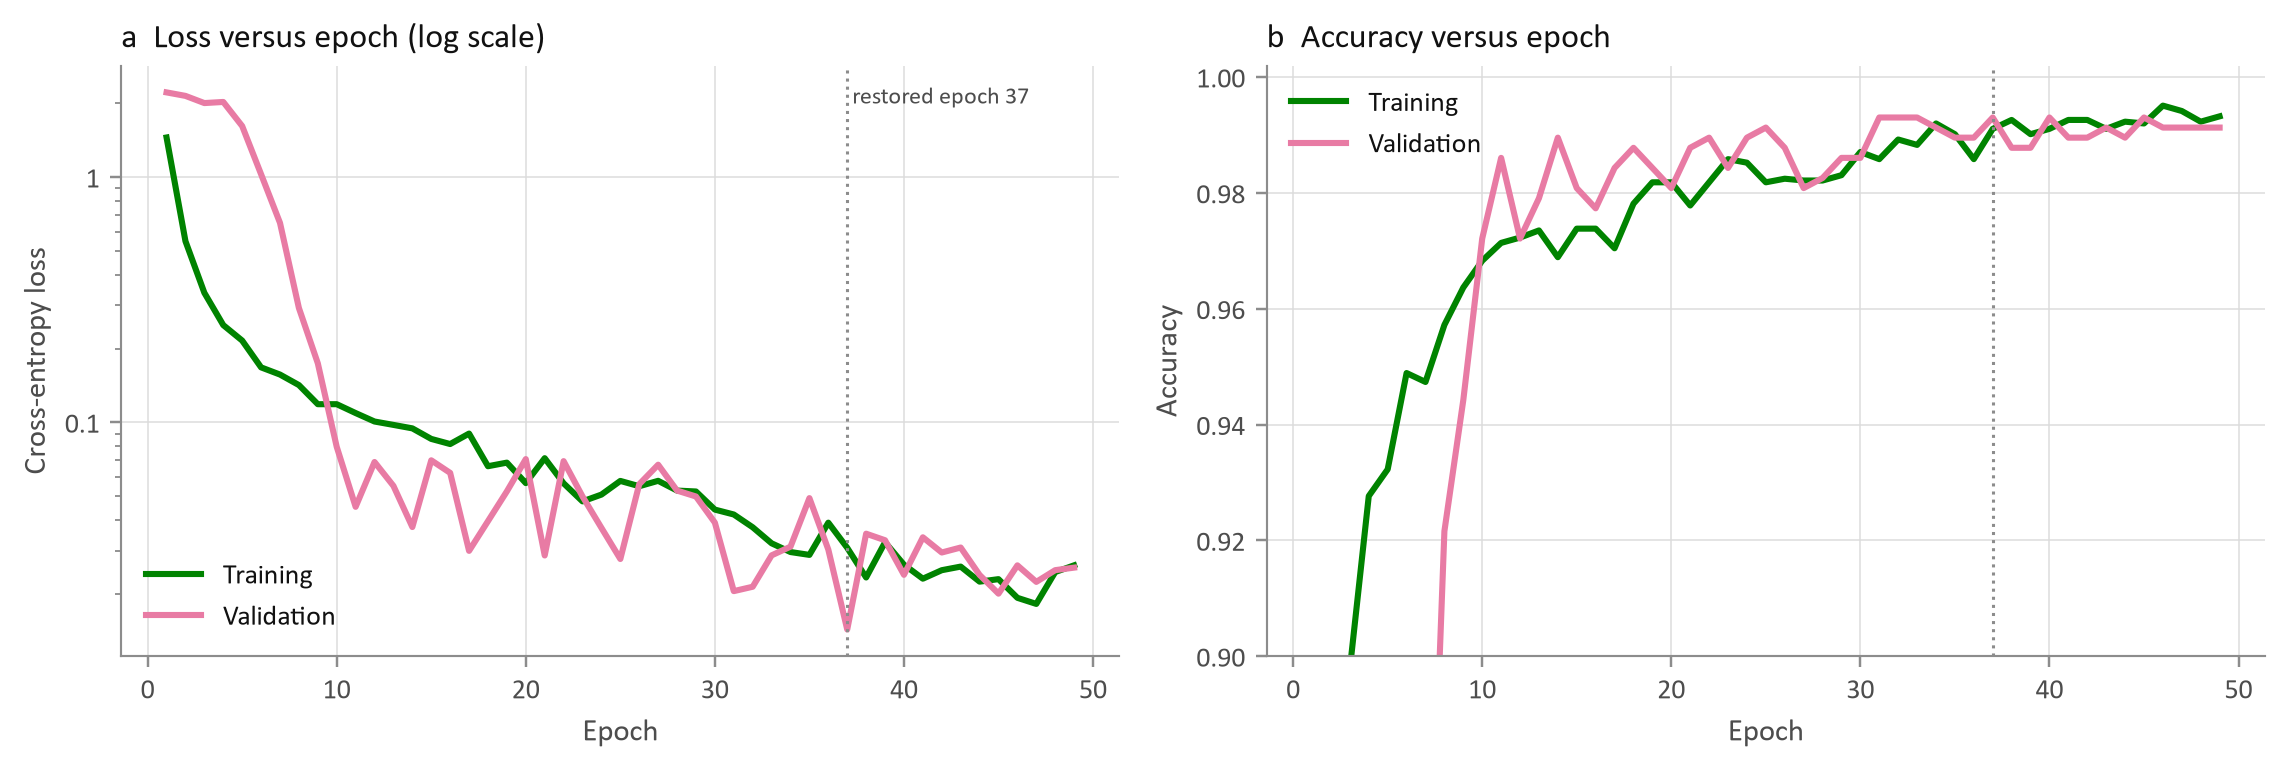

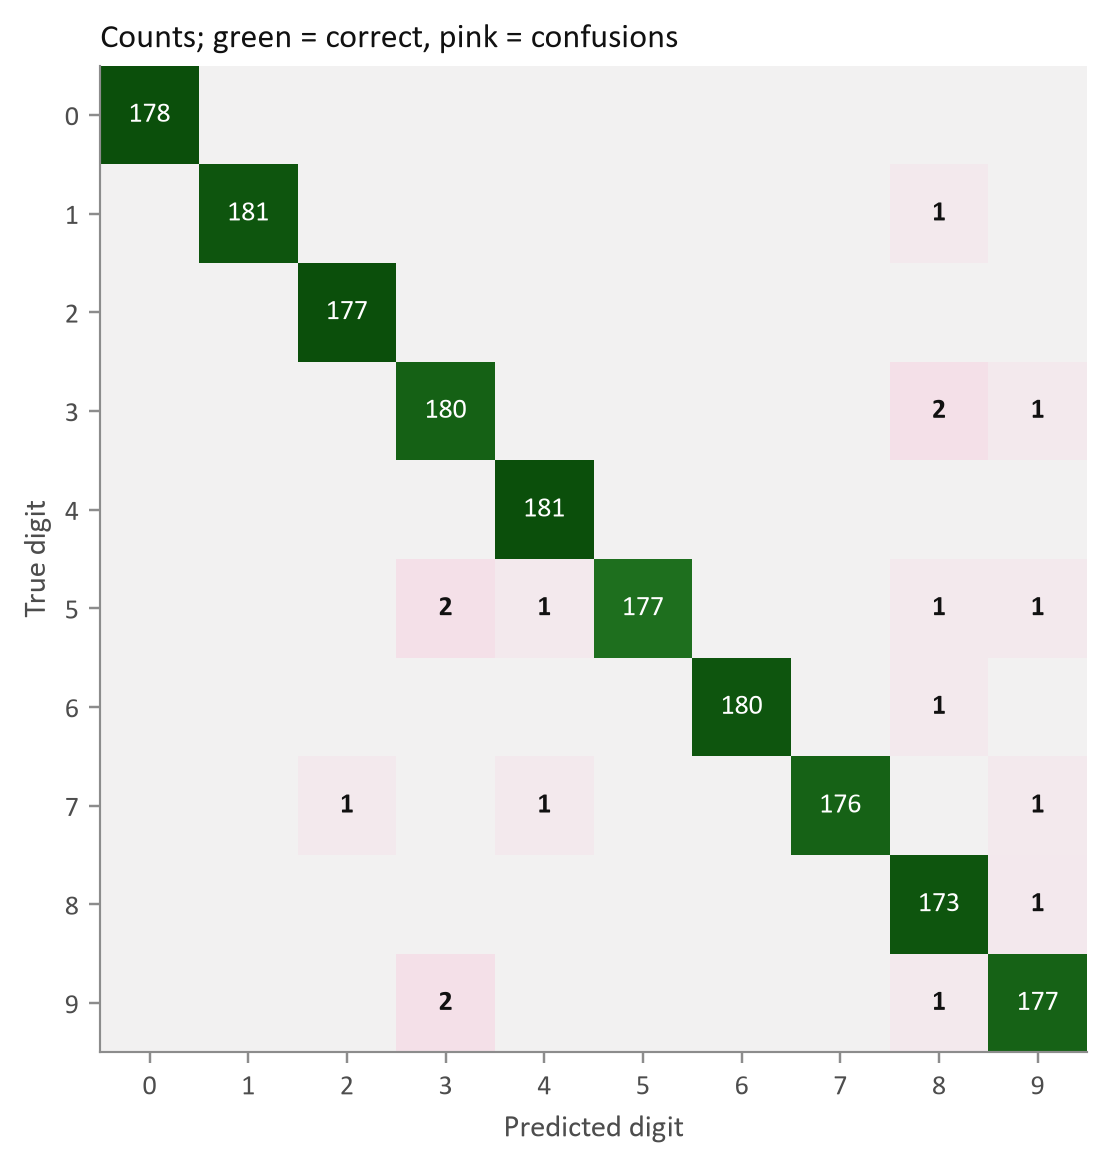

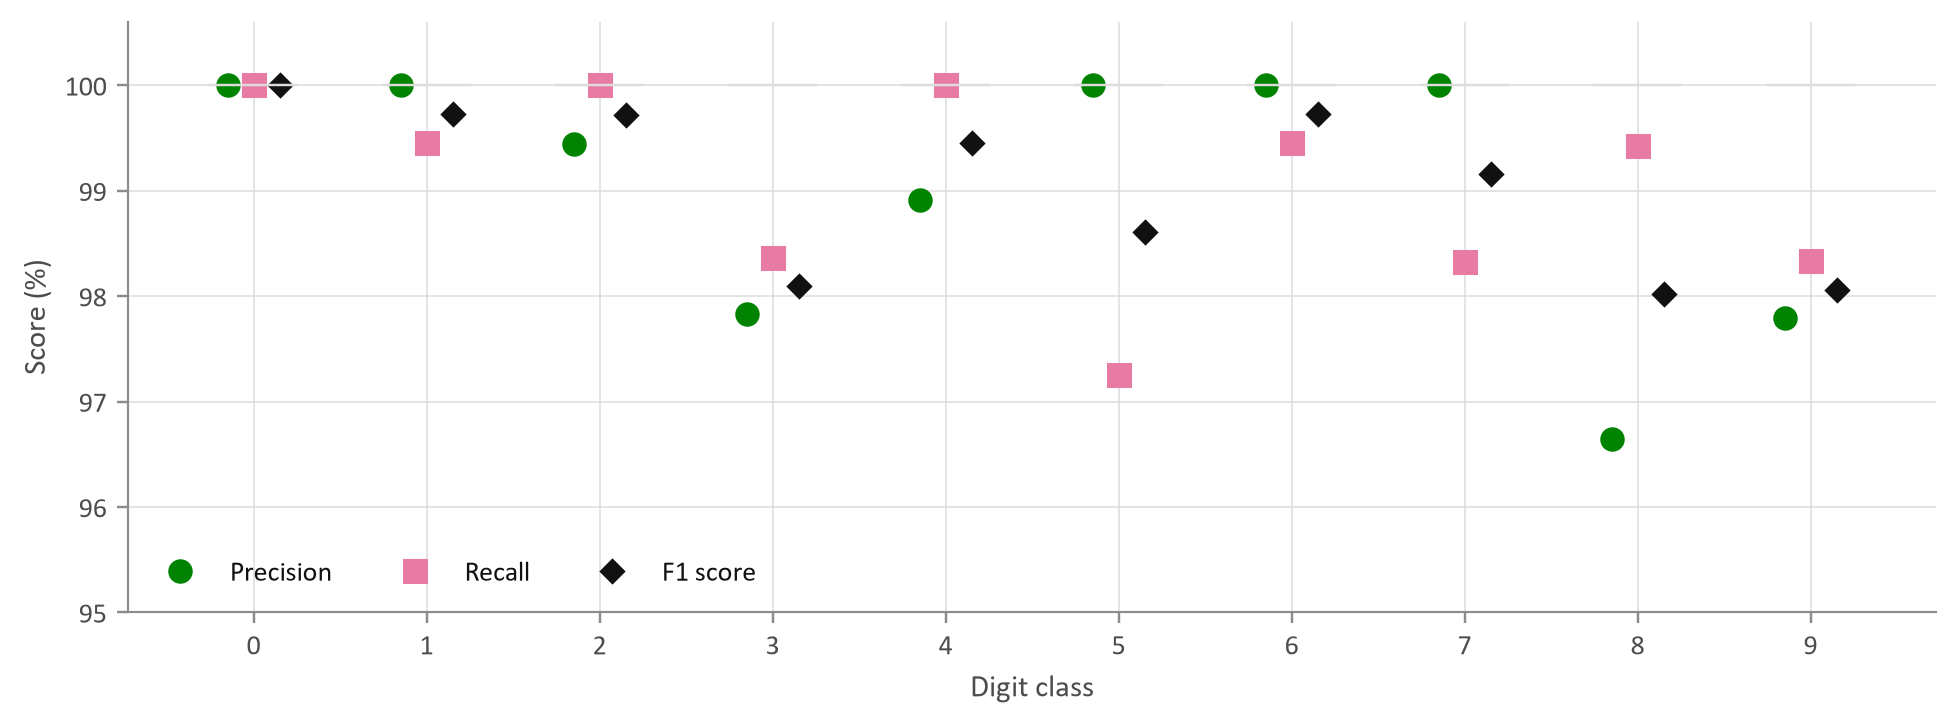

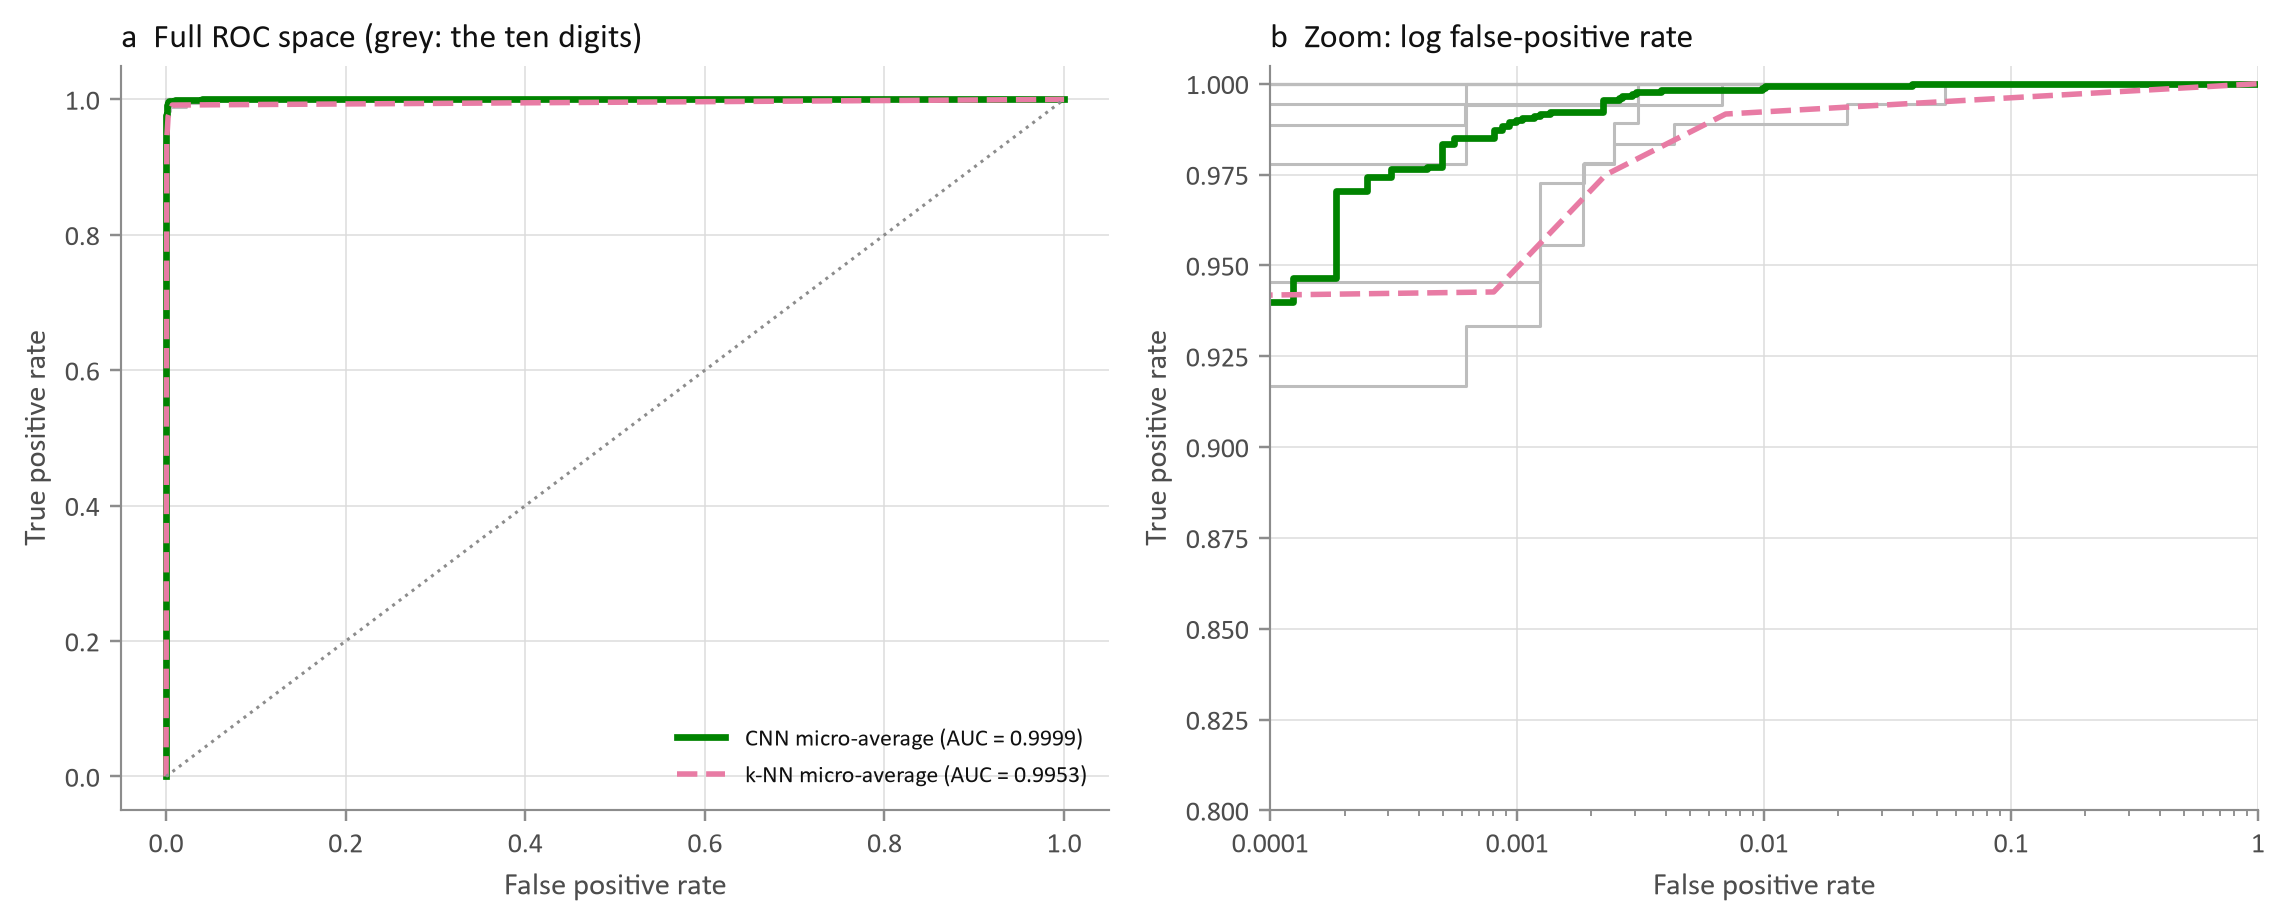

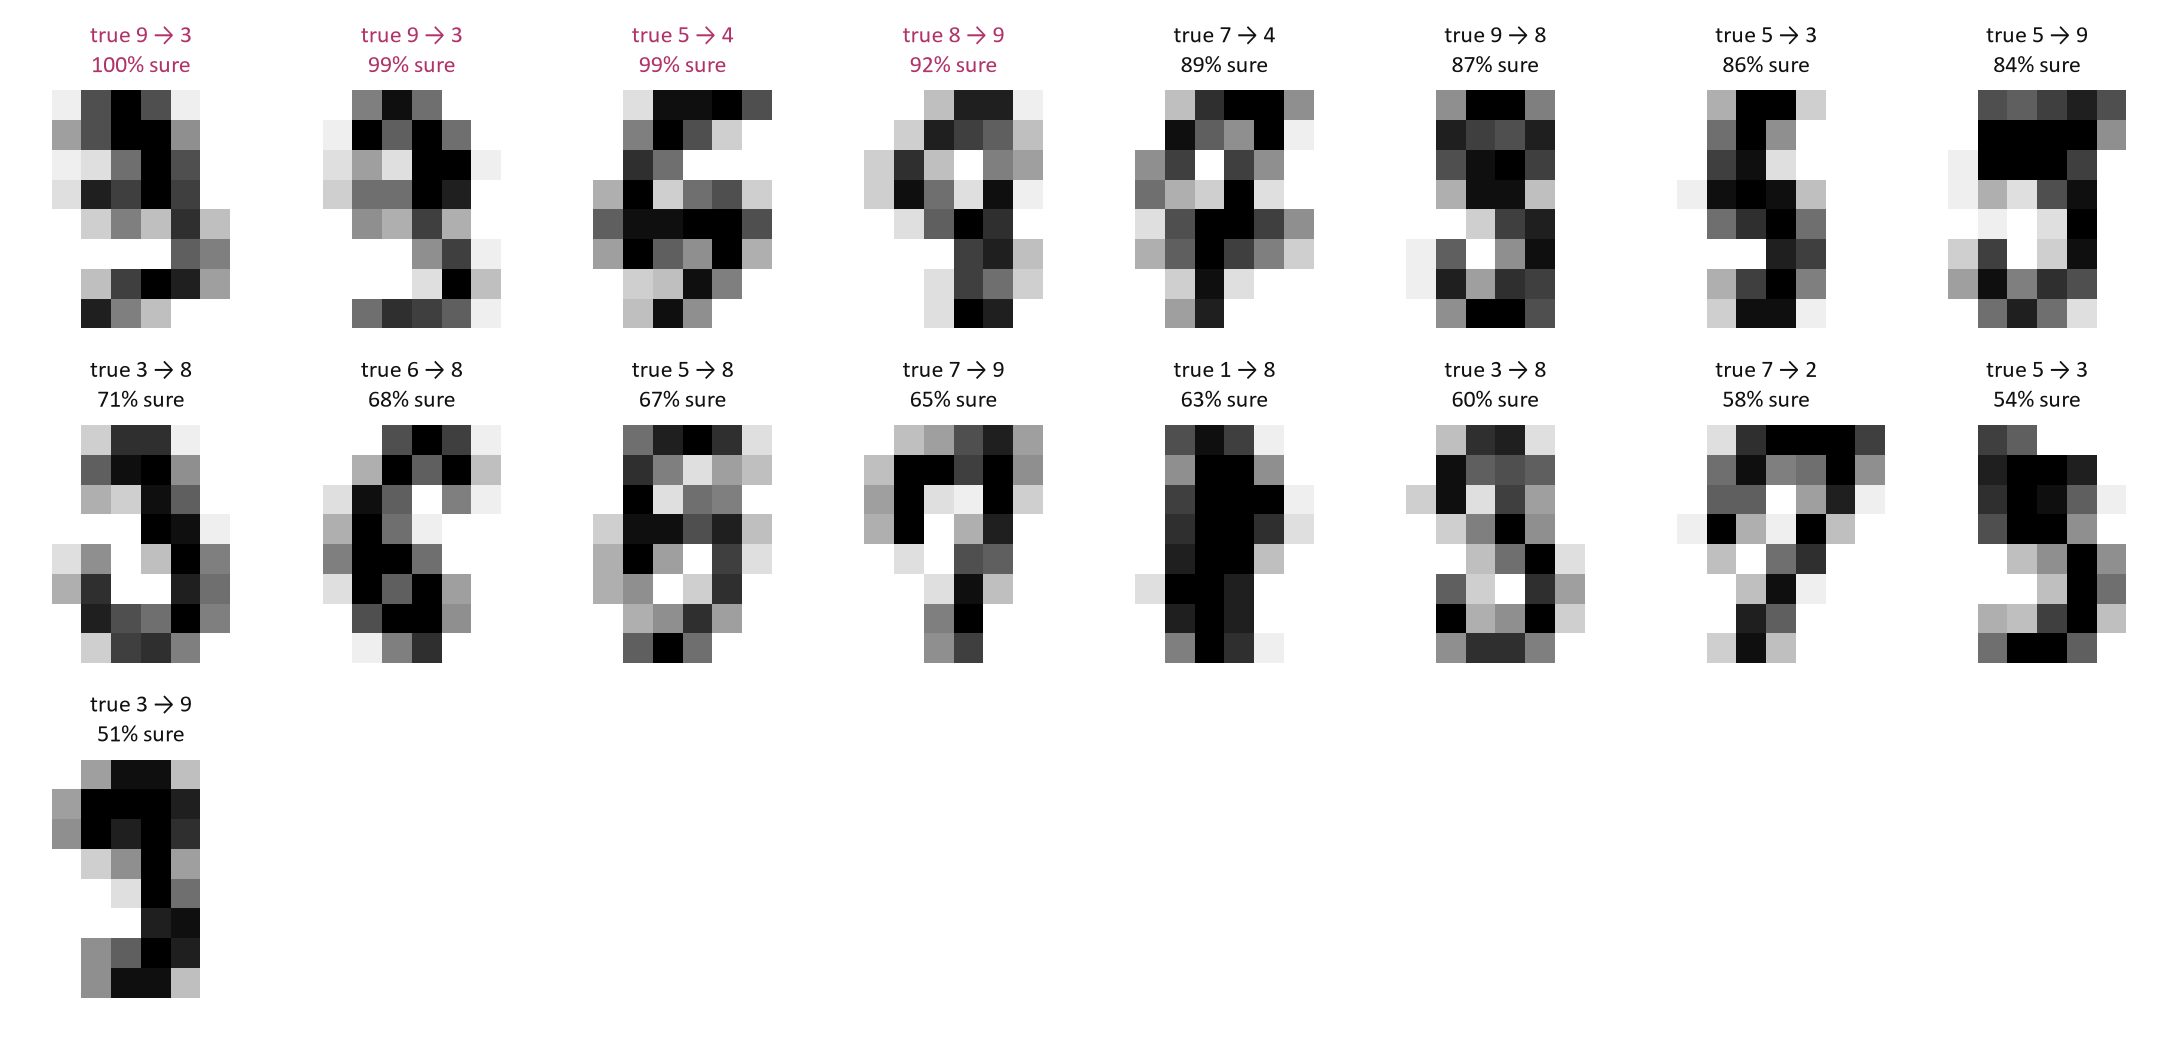

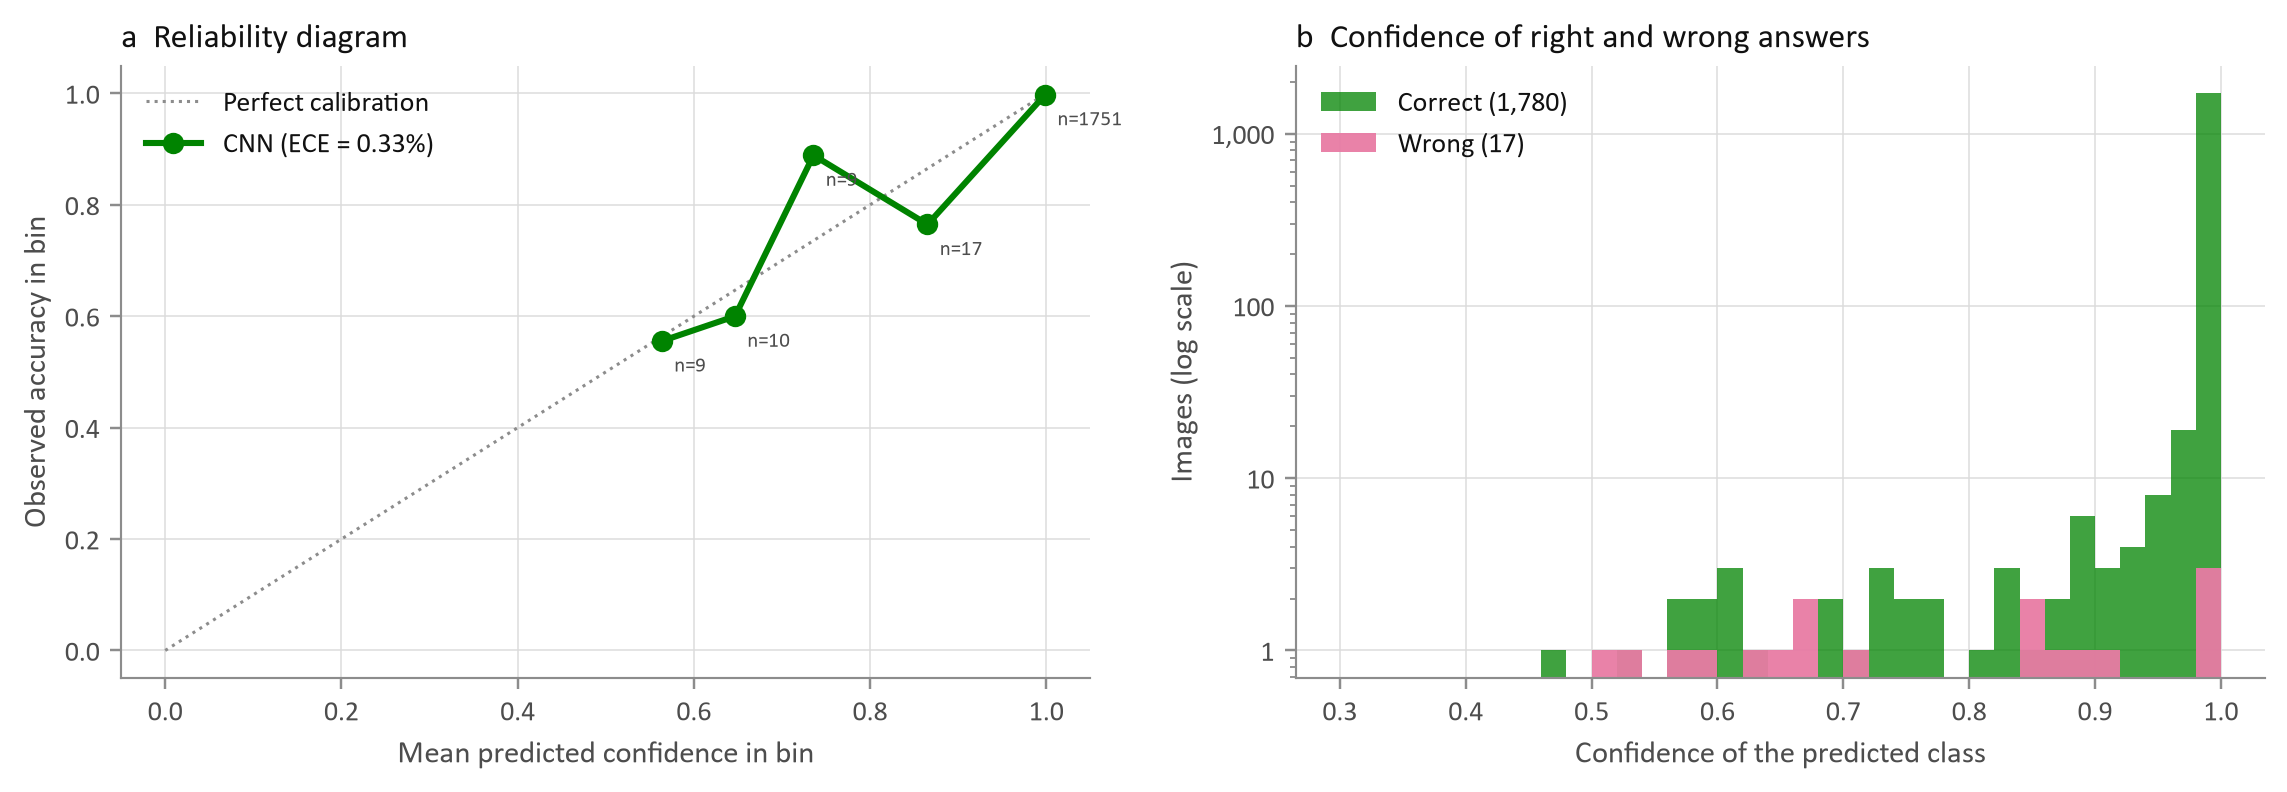

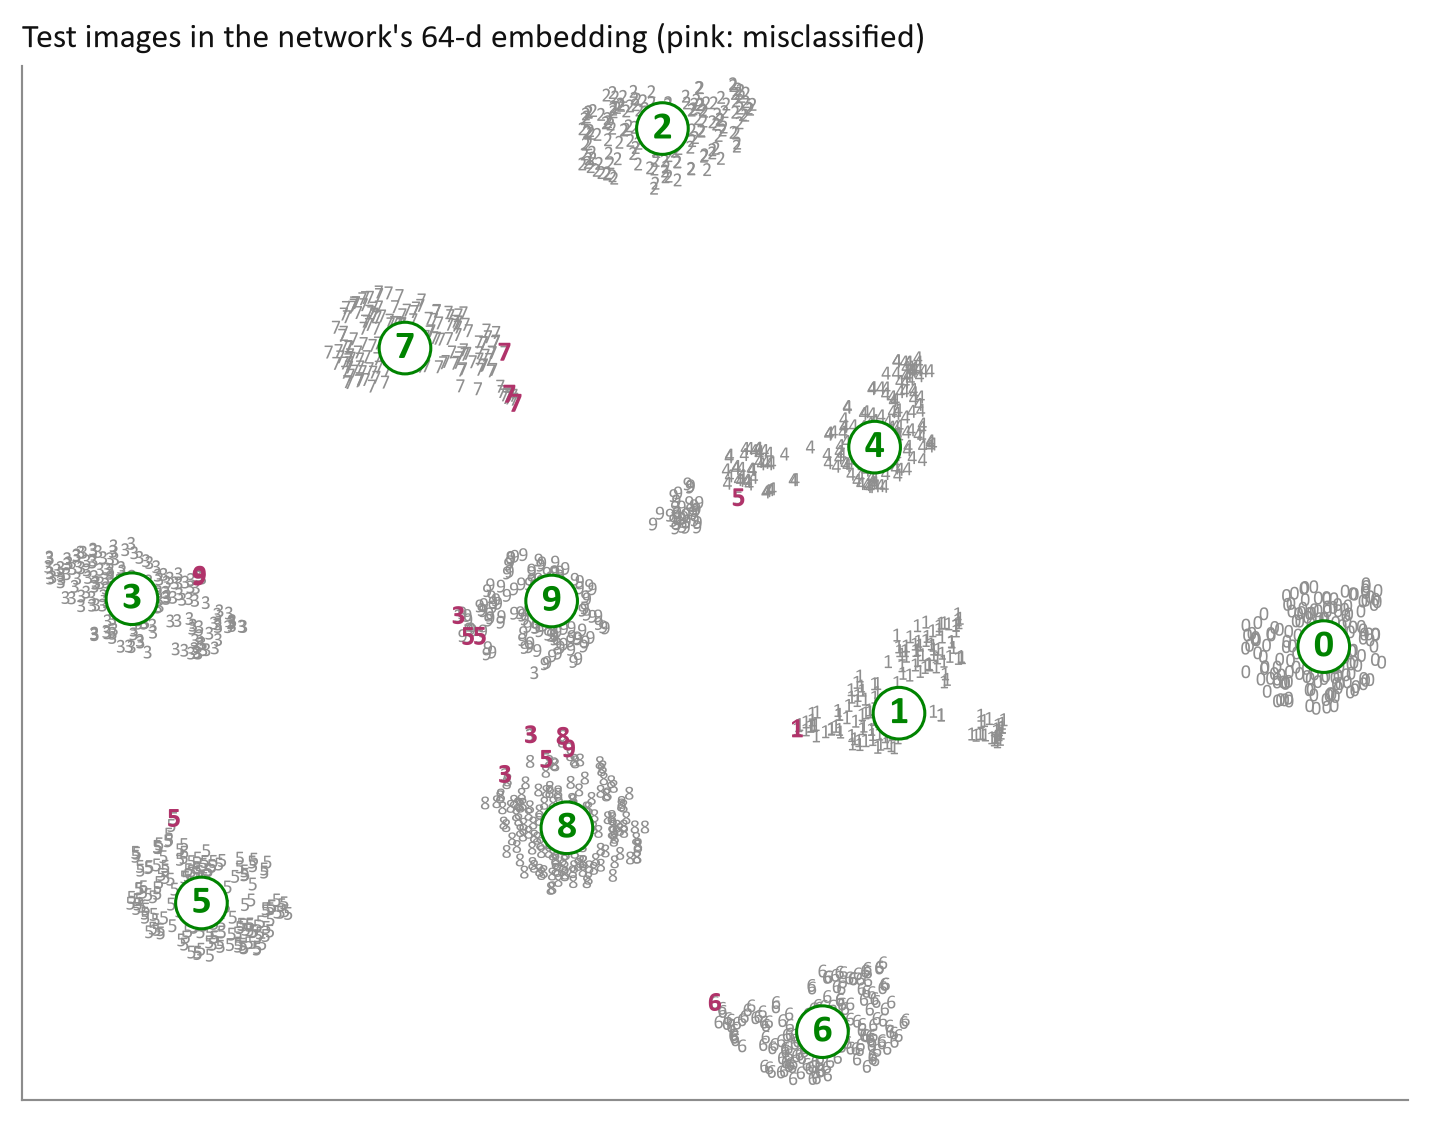

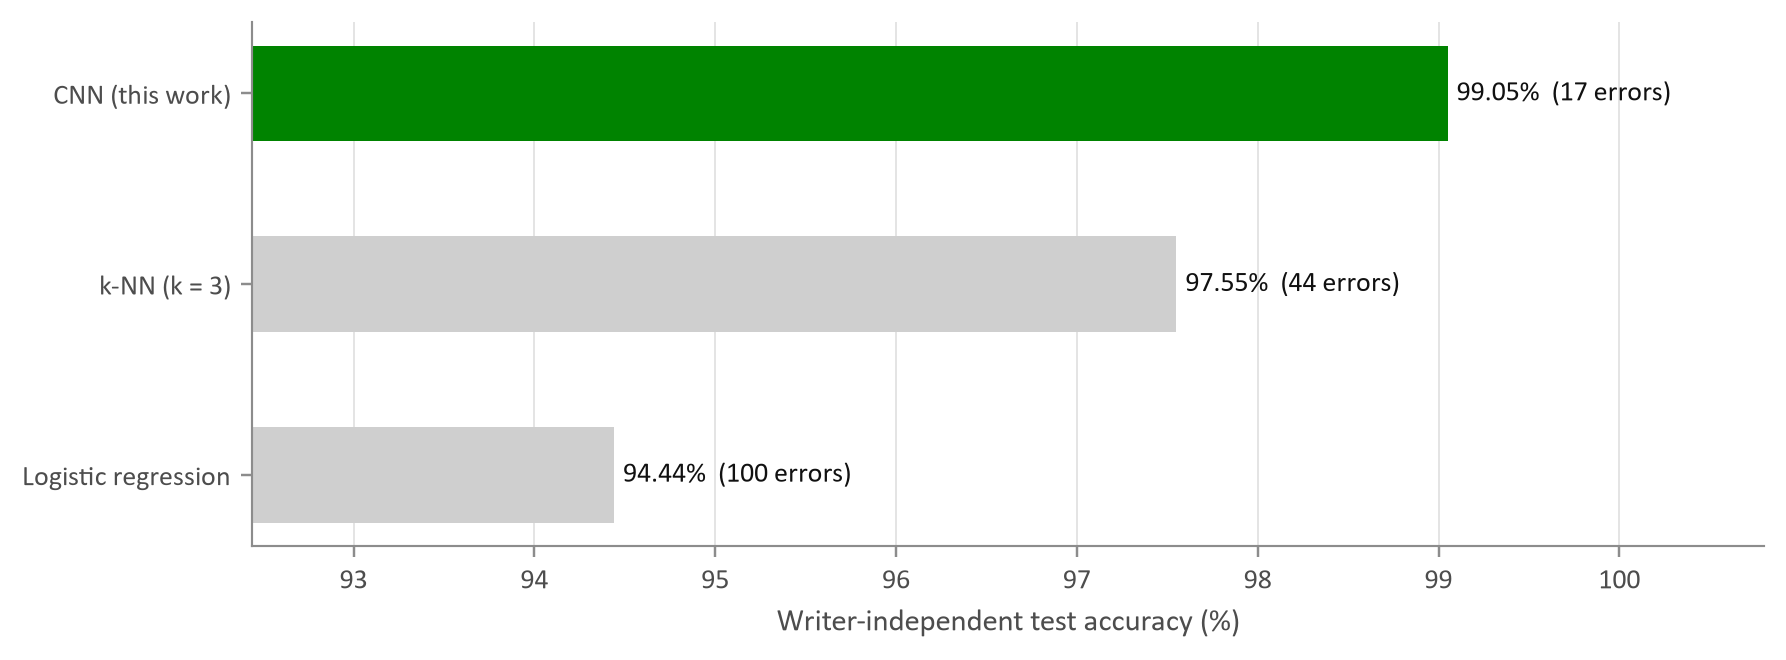

In [9]:
show('m03_learning_curves', 'm04_confusion_matrix', 'm05_per_class_scores', 'm06_roc_curves', 'm07_misclassified', 'm08_calibration', 'm09_embedding_tsne', 'm10_model_comparison')

## 5. Interact
Open `dashboard/index.html` in a browser to draw your own digit and to explore the test-set predictions.

In [10]:
%run step5_dashboard.py

written C:\Users\nakul\AppData\Roaming\Claude\scratch-workspaces\635db47b-82a4-4829-a53f-a8bb9dba6efa\bf12d992-1e38-4815-99e9-735d88a9c900\scratch-2026-10-12-3f46f7\Vinith_25ADL10\dashboard\index.html
